# Ricostruzione e Imputazione Avanzata di Serie Storiche di Traffico

Il presente notebook illustra il processo completo di imputazione e ricostruzione dei dati mancanti (*Data Imputation*) all'interno di serie storiche relative al traffico veicolare.

Si applica un algoritmo customizzato basato sulla ricerca di periodi analoghi (simil-KNN) e sull'iniezione di varianza locale, ottimizzato tramite Grid Search bidirezionale. L'obiettivo è colmare gap temporali estesi garantendo la coerenza statistica, la preservazione dei pattern orari pendolari e l'adattamento ai cali fisiologici legati alla stagionalità (es. periodo estivo).

Il processo culmina con una validazione avanzata che analizza le metriche di errore e la forma delle distribuzioni sia su scala Macro (mensile) che Micro (settimane adiacenti).

## 1. Importazione Librerie e Pre-elaborazione Dati
In questa prima fase si importano le librerie necessarie (Pandas, NumPy, Seaborn, Matplotlib, ecc.) e si effettua il montaggio dell'ambiente Google Drive per l'accesso ai file. Successivamente, si caricano i dataset storici (traffico e anagrafica stazioni). Si eseguono le operazioni di pulizia strutturale, il parsing rigoroso dei formati data/ora e la creazione della variabile target `differenza` (traffico libero vs attuale), assicurandosi di imporre il limite fisico dello zero.

In [38]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.metrics import mean_absolute_error
from google.colab import drive

# ==========================================
# 1. CARICAMENTO E PRE-ELABORAZIONE
# ==========================================
print("Montaggio Google Drive e caricamento dati...")
drive.mount('/content/drive')

path_traffico = '/content/drive/MyDrive/Colab Notebooks/TIROCINIO/dataset_originale/traffico.csv'
path_stazioni = '/content/drive/MyDrive/Colab Notebooks/TIROCINIO/dataset_originale/stazioni.csv'

df_tr = pd.read_csv(path_traffico)
df_st = pd.read_csv(path_stazioni)

df_tr.columns = df_tr.columns.str.strip()
df_st.columns = df_st.columns.str.strip()

df_tr['giorno'] = pd.to_datetime(df_tr['giorno'], errors='coerce')
df_tr['orario'] = df_tr['orario'].astype(str).str.strip()
df_tr['timestamp'] = pd.to_datetime(df_tr['giorno'].astype(str) + " " + df_tr['orario'], errors='coerce')

df_tr['velocita_attuale'] = pd.to_numeric(df_tr['velocita_attuale'], errors='coerce')
df_tr['velocita_senza_traffico'] = pd.to_numeric(df_tr['velocita_senza_traffico'], errors='coerce')

df_tr['differenza'] = df_tr['velocita_senza_traffico'] - df_tr['velocita_attuale']
df_tr['differenza'] = df_tr['differenza'].clip(lower=0)

df = df_tr.merge(df_st, left_on='id_stazione', right_on='id', how='left')
df = df.dropna(subset=['timestamp', 'differenza']).sort_values(['id_stazione', 'timestamp']).reset_index(drop=True)

df['month'] = df['timestamp'].dt.month
df['hour'] = df['timestamp'].dt.hour
df['weekday'] = df['timestamp'].dt.weekday

Montaggio Google Drive e caricamento dati...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Funzioni per la Ricostruzione
Qui si definiscono le funzioni matematiche centrali dell'algoritmo:
1. **Ricerca Periodi Analoghi (`find_analogous_periods`)**: Seleziona i giorni storici più simili utilizzando una gerarchia di punteggi rigida (Ora > Giorno > Recenza Bidirezionale).
2. **Ricostruzione per Campionamento (`reconstruct_station_by_sampling`)**: Calcola il valore atteso aggregando i candidati scelti e iniettando una perturbazione gaussiana basata sulla sola varianza locale. Applica un limite calcolato sulla media dei picchi pre e post gap.
3. **Cross-Validation a 1 Settimana (`grid_search_reconstruction`)**: Cerca i parametri ottimali simulando buchi finti nei giorni strettamente adiacenti al gap reale.
4. **Sfumatura (`smooth_transitions`)**: Garantisce la continuità della curva ai bordi del gap.

Nello specifico queste sono le 4 funzioni principali:

1.  **`find_analogous_periods` (Ricerca Storica Bidirezionale)**
    Questa funzione ha il compito di trovare i giorni passati (o futuri) che più assomigliano al momento che si sta tentando di ricostruire. Per farlo, non usa una semplice finestra temporale, ma applica una **Gerarchia Rigida di Punteggi**:
    * **Ora esatta (+100 punti):** Garantisce che le dinamiche del mattino non vengano mai confuse con quelle serali o notturne.
    * **Giorno della settimana (+50 punti):** Mantiene la separazione critica tra i giorni feriali (pendolarismo) e i festivi.
    * **Recenza Bidirezionale (+20 punti a scalare):** Funge da *tie-breaker*. Se l'algoritmo trova molti "Lunedì alle 08:00", preferirà quelli temporalmente più vicini al buco da coprire. La misurazione è bidirezionale: se si sta ricostruendo la prima metà del buco, cercherà i giorni passati adiacenti; se si sta ricostruendo la seconda metà, darà priorità ai giorni futuri adiacenti. Questo garantisce un perfetto ancoraggio alla stagionalità locale.

2.  **`reconstruct_station_by_sampling` (Imputazione con Iniezione Stocastica)**
    È qui che avviene la generazione materiale del dato. Per ogni singolo slot di tempo mancante (es. 10 minuti), l'algoritmo estrae i candidati ottimali calcolati dalla funzione precedente.
    * **Valore Base:** Viene calcolata la media aritmetica dei candidati migliori.
    * **Iniezione del Rumore:** L'algoritmo calcola quindi la **Deviazione Standard Locale** all'interno dei candidati stessi. Se i candidati storici oscillavano molto (traffico instabile), la deviazione standard sarà alta. Se i candidati erano tutti a zero (strada libera), la deviazione sarà zero. Questo valore diventa il parametro `scale` di una distribuzione Gaussiana (Normale). L'algoritmo "lancia un dado" seguendo questa curva a campana e somma il risultato al Valore Base. In questo modo, le strade storicamente fluide rimangono piatte a zero, mentre i momenti di congestione mantengono una naturale turbolenza.

3.  **`grid_search_reconstruction` (Ottimizzazione dei Parametri via Cross-Validation)**
    L'algoritmo non utilizza parametri fissi per tutte le stazioni geografiche. Prima di ricostruire il gap reale, questa funzione crea due "finti buchi" della durata di 7 giorni immediatamente prima e immediatamente dopo il periodo mancante reale. Testa diverse combinazioni di parametri (quanti candidati storici guardare e quanti usarne per la media) confrontando i dati generati con i dati reali nascosti, calcolando il *Mean Absolute Error* (MAE). I parametri che minimizzano l'errore nel micro-contesto locale verranno poi utilizzati per l'imputazione definitiva.

4.  **`smooth_transitions` (Raccordo ai Bordi)**
    Infine, per garantire che non vi siano "scalini" innaturali nel momento in cui la serie storica reale si interrompe e inizia quella ricostruita (e viceversa), questa funzione applica una sfumatura lineare. Funziona come un *fade-in* e un *fade-out* audio: i primi e gli ultimi dati generati vengono ponderatamente miscelati con la media mobile dei dati reali immediatamente adiacenti, garantendo una continuità fluida e senza strappi.

In [39]:
# ==========================================
# 2. FUNZIONI CORE CON GERARCHIA RIGIDA
# ==========================================

def find_analogous_periods(df_valid, target_timestamp, gap_start, gap_end, n_candidates=15):
    """
    Cerca nel dataset storico i momenti più simili (analoghi) al timestamp che stiamo cercando di ricostruire.
    Usa un sistema a punti gerarchico: l'ora è fondamentale, il giorno è importante, la vicinanza temporale è il tie-breaker.
    """
    target_weekday = target_timestamp.weekday()
    target_hour = target_timestamp.hour

    hours = df_valid['hour'].values
    weekdays = df_valid['weekday'].values
    diffs = df_valid['differenza'].values

    # --- CALCOLO DELLA DISTANZA BIDIREZIONALE ---
    # Troviamo la distanza per misurare quanto un giorno storico è vicino al buco
    target_ns = target_timestamp.value
    start_ns = gap_start.value
    end_ns = gap_end.value

    # Calcoliamo il punto medio del buco per capire se siamo nella prima o seconda metà
    mid_point_ns = start_ns + (end_ns - start_ns) / 2
    timestamps_ns = df_valid['timestamp'].values.astype(np.int64)

    # Se stiamo ricostruendo la prima metà del buco, la recenza si calcola dall'inizio del buco
    if target_ns <= mid_point_ns:
        days_diff = np.abs(timestamps_ns - start_ns) / (1e9 * 3600 * 24)
    # Altrimenti si calcola dalla fine del buco (guardando verso il futuro)
    else:
        days_diff = np.abs(timestamps_ns - end_ns) / (1e9 * 3600 * 24)

    scores = np.zeros(len(df_valid))

    # --- ASSEGNAZIONE PUNTEGGI (GERARCHIA RIGIDA) ---
    # 1. L'Ora esatta (+100): Priorità assoluta. Le 08:00 non possono mai essere scambiate per le 15:00
    scores += np.where(hours == target_hour, 100, 0)

    # 2. Il Giorno esatto (+50): Distingue giorni feriali da festivi
    scores += np.where(weekdays == target_weekday, 50, 0)

    # 3. Recenza (+20 a scalare): Premia i giorni della stessa stagione/settimana adiacente.
    # Essendo un punteggio massimo di 20 (minore di 50), la recenza funge solo da spareggio
    scores += np.maximum(0, 20 - (days_diff / 3))

    # 4. Bonus di tolleranza per ore limitrofe: Se non trova esattamente le 08:00, le 07:50 o le 08:10 prendono punti parziali.
    hour_diff = np.abs(hours - target_hour)
    hour_diff = np.minimum(hour_diff, 24 - hour_diff)
    scores += np.maximum(0, 10 - hour_diff)

    # --- ESTRAZIONE DEI MIGLIORI ---
    # Ordina i punteggi in modo decrescente e prende i primi 'n_candidates' (es. i migliori 15)
    top_indices = np.argsort(-scores)[:n_candidates]
    best_diffs = diffs[top_indices]

    # # --- FILTRO OUTLIER LOCALE ---
    # # Rimuove eventuali valori anomali (es. un incidente isolato a 40 km/h) all'interno dei candidati scelti.
    # mean_val = np.mean(best_diffs)
    # std_val = np.std(best_diffs)
    # if std_val > 0:
    #     mask = (best_diffs >= mean_val - 2*std_val) & (best_diffs <= mean_val + 2*std_val)
    #     filtered = best_diffs[mask]
    #     if len(filtered) >= 5:
    #         return filtered

    return best_diffs


def reconstruct_station_by_sampling(df_station, gap_start, gap_end, freq, n_candidates=15, n_sample=5):
    """
    Versione corretta: introduce il campionamento casuale (shuffle) tra i candidati
    per evitare la saturazione da zeri nelle stazioni a basso traffico.
    """
    missing_timestamps = pd.date_range(start=gap_start + freq, end=gap_end - freq, freq=freq)
    if len(missing_timestamps) == 0:
        return pd.DataFrame()

    df_valid = df_station[
        (df_station['month'] != 8) &
        ((df_station['timestamp'] < gap_start) | (df_station['timestamp'] > gap_end))
    ].copy()

    if df_valid.empty:
        return pd.DataFrame({'timestamp': missing_timestamps, 'differenza': 0})

    # Calcolo tetto picchi adiacenti
    pre_week = df_valid[(df_valid['timestamp'] >= gap_start - pd.Timedelta(days=7)) & (df_valid['timestamp'] < gap_start)]
    post_week = df_valid[(df_valid['timestamp'] > gap_end) & (df_valid['timestamp'] <= gap_end + pd.Timedelta(days=7))]
    max_pre = pre_week['differenza'].max() if not pre_week.empty else np.nan
    max_post = post_week['differenza'].max() if not post_week.empty else np.nan

    with np.errstate(invalid='ignore'):
        tetto_assoluto = np.nanmean([max_pre, max_post])
    if pd.isna(tetto_assoluto) or tetto_assoluto <= 0:
        tetto_assoluto = df_valid['differenza'].max()

    reconstructed_values = []
    fallback_mean = df_valid['differenza'].mean()

    for ts in missing_timestamps:
        candidates = find_analogous_periods(df_valid, ts, gap_start, gap_end, n_candidates=n_candidates)

        if candidates is not None and len(candidates) > 0:
            # --- SOLUZIONE: SHUFFLE DEI CANDIDATI ---
            # Invece di prendere i primi N (spesso zeri), mescoliamo i candidati
            # migliori per dare una chance anche ai giorni con traffico reale.
            available_indices = np.arange(len(candidates))
            selected_indices = np.random.choice(available_indices, size=min(n_sample, len(candidates)), replace=False)
            chosen_samples = candidates[selected_indices]

            base_value = np.mean(chosen_samples)
            local_sigma = np.std(chosen_samples)
        else:
            base_value = fallback_mean
            local_sigma = 0

        noise = np.random.normal(loc=0, scale=local_sigma) if local_sigma > 0 else 0
        value = np.clip(base_value + noise, 0, tetto_assoluto)
        reconstructed_values.append(value)

    return pd.DataFrame({'timestamp': missing_timestamps, 'differenza': reconstructed_values})

def grid_search_reconstruction(df_station, gap_start, gap_end, freq, param_grid):
    """
    Ottimizza i parametri n_candidates e n_sample simulando "finti buchi" prima e dopo il buco reale.
    Garantisce che l'algoritmo venga calibrato sul comportamento specifico del traffico estivo.
    """
    test_gaps = []

    # Crea un finto buco di test di 7 giorni immediatamente precedente al gap
    test_start_pre = gap_start - pd.Timedelta(days=7)
    test_end_pre = gap_start

    # Crea un finto buco di test di 7 giorni immediatamente successivo al gap
    test_start_post = gap_end
    test_end_post = gap_end + pd.Timedelta(days=7)

    # Controlla che ci siano dati storici validi per fare il test
    if len(df_station[(df_station['timestamp'] >= test_start_pre) & (df_station['timestamp'] < test_end_pre)]) > 100:
        test_gaps.append((test_start_pre, test_end_pre))

    if len(df_station[(df_station['timestamp'] > test_start_post) & (df_station['timestamp'] <= test_end_post)]) > 100:
        test_gaps.append((test_start_post, test_end_post))

    if not test_gaps:
        print("      [!] Dati di test adiacenti insufficienti, uso default.")
        return {'n_candidates': 15, 'n_sample': 5}

    best_mae = float('inf')
    best_params = None

    # Genera tutte le combinazioni possibili di parametri dalla griglia
    keys, values = zip(*param_grid.items())
    combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

    # Testa ogni combinazione e calcola il Mean Absolute Error (MAE)
    for params in combinations:
        maes_for_this_param = []
        for t_start, t_end in test_gaps:
            mask_test = (df_station['timestamp'] > t_start) & (df_station['timestamp'] < t_end)
            df_test_real = df_station[mask_test]

            if df_test_real.empty:
                continue

            rec_test = reconstruct_station_by_sampling(
                df_station, t_start, t_end, freq,
                n_candidates=params['n_candidates'], n_sample=params['n_sample']
            )

            # Confronta il dato reale con il finto ricostruito
            merged = pd.merge(df_test_real[['timestamp', 'differenza']], rec_test, on='timestamp', suffixes=('_true', '_pred'))
            if not merged.empty:
                mae = mean_absolute_error(merged['differenza_true'], merged['differenza_pred'])
                maes_for_this_param.append(mae)

        if maes_for_this_param:
            avg_mae = np.mean(maes_for_this_param)
            print(f"      [Test] Parametri {params}")
            # Salva la combinazione che restituisce l'errore minore
            if avg_mae < best_mae:
                best_mae = avg_mae
                best_params = params

    return best_params if best_params else combinations[0]


def smooth_transitions(df_station, gap_start, gap_end, reconstructed, n_blend=24):
    """
    Applica una sfumatura (fade-in e fade-out) ai bordi estremi del dato ricostruito
    per evitare uno scalino nel punto in cui il dato finto si attacca a quello reale.
    'n_blend' indica su quanti punti spalmare la transizione (es. 24 slot).
    """
    if reconstructed.empty:
        return reconstructed

    # Prende gli ultimi dati prima del buco e i primi dati dopo il buco
    pre_gap = df_station[(df_station['timestamp'] < gap_start) &
                         (df_station['timestamp'] >= gap_start - pd.Timedelta(hours=n_blend))].sort_values('timestamp')
    post_gap = df_station[(df_station['timestamp'] > gap_end) &
                          (df_station['timestamp'] <= gap_end + pd.Timedelta(hours=n_blend))].sort_values('timestamp')

    values = reconstructed['differenza'].values.copy()

    # --- SFUMATURA INIZIALE (FADE-IN) ---
    if len(pre_gap) > 0:
        n_blend_start = min(n_blend, len(values) // 4)
        pre_mean = pre_gap['differenza'].tail(5).mean()
        for i in range(n_blend_start):
            weight = i / n_blend_start
            # Più ci si allontana dal bordo, più il 'weight' sposta l'equilibrio dal dato reale verso il dato finto
            values[i] = (1 - weight) * pre_mean + weight * values[i]

    # --- SFUMATURA FINALE (FADE-OUT) ---
    if len(post_gap) > 0:
        n_blend_end = min(n_blend, len(values) // 4)
        post_mean = post_gap['differenza'].head(5).mean()
        for i in range(n_blend_end):
            idx = len(values) - n_blend_end + i
            weight = i / n_blend_end
            # Transizione fluida in uscita per ricollegarsi al dato reale post-gap
            values[idx] = (1 - weight) * values[idx] + weight * post_mean

    reconstructed['differenza'] = values
    return reconstructed

## 3. Identificazione Gap ed Esecuzione
In questa sezione si calcola automaticamente l'intervallo temporale mancante globale. Si itera poi su ogni singola stazione, applicando prima la Grid Search per individuare i migliori iperparametri locali e avviando successivamente l'imputazione. I dati ricostruiti vengono collezionati in un array globale.

In [40]:
# ==========================================
# 3. IDENTIFICAZIONE GAP E ESECUZIONE
# ==========================================

stazioni = sorted(df['id_stazione'].unique())

df_sample = df[df['id_stazione'] == stazioni[0]].copy()
df_sample['time_diff'] = df_sample['timestamp'].diff()
freq = df_sample['time_diff'].mode()[0]
gap_idx = df_sample['time_diff'].idxmax()
gap_start = df_sample.loc[gap_idx - 1, 'timestamp']
gap_end = df_sample.loc[gap_idx, 'timestamp']

print(f"\nGap Globale Individuato: {gap_start} -> {gap_end}")

PARAM_GRID = {
    'n_candidates': [5, 10, 15, 20],
    'n_sample': [3, 5, 7]
}

all_reconstructed = []
print("\nInizio Ricostruzione con Gerarchia Rigida & Tetto Picchi Adiacenti...")

for st in stazioni:
    print(f"\n➜ Elaborazione Stazione {st}:")
    df_st = df[df['id_stazione'] == st].copy()

    best_params = grid_search_reconstruction(df_st, gap_start, gap_end, freq, PARAM_GRID)
    print(f"  [!] Scelto per Stazione {st} -> {best_params}")

    reconstructed = reconstruct_station_by_sampling(
        df_st, gap_start, gap_end, freq,
        n_candidates=best_params['n_candidates'],
        n_sample=best_params['n_sample']
    )

    if reconstructed.empty:
        continue

    reconstructed = smooth_transitions(df_st, gap_start, gap_end, reconstructed)
    reconstructed['id_stazione'] = st
    all_reconstructed.append(reconstructed)


Gap Globale Individuato: 2025-06-25 15:34:39 -> 2025-07-16 23:30:02

Inizio Ricostruzione con Gerarchia Rigida & Tetto Picchi Adiacenti...

➜ Elaborazione Stazione 1:
      [Test] Parametri {'n_candidates': 5, 'n_sample': 3}
      [Test] Parametri {'n_candidates': 5, 'n_sample': 5}
      [Test] Parametri {'n_candidates': 5, 'n_sample': 7}
      [Test] Parametri {'n_candidates': 10, 'n_sample': 3}
      [Test] Parametri {'n_candidates': 10, 'n_sample': 5}
      [Test] Parametri {'n_candidates': 10, 'n_sample': 7}
      [Test] Parametri {'n_candidates': 15, 'n_sample': 3}
      [Test] Parametri {'n_candidates': 15, 'n_sample': 5}
      [Test] Parametri {'n_candidates': 15, 'n_sample': 7}
      [Test] Parametri {'n_candidates': 20, 'n_sample': 3}
      [Test] Parametri {'n_candidates': 20, 'n_sample': 5}
      [Test] Parametri {'n_candidates': 20, 'n_sample': 7}
  [!] Scelto per Stazione 1 -> {'n_candidates': 20, 'n_sample': 3}

➜ Elaborazione Stazione 2:
      [Test] Parametri {'n_candi

## 4. Salvataggio e Grafici Panoramici
Una volta terminata l'elaborazione, le porzioni imputate vengono fuse con il dataset storico depurato da eventuali record corrotti interni al gap. Il dataframe finale (`df_final`) viene salvato come CSV sul Drive.
Vengono poi generati due blocchi di visualizzazione (matrici di grafici) per l'ispezione visiva della continuità della serie: uno zoom a 30 giorni e una prospettiva ampia a 90 giorni.


Ricostruzione Completata! Punti imputati: 27585
Dati salvati in: '/content/drive/MyDrive/Colab Notebooks/TIROCINIO/dataset_ricostruito/traffico_r2.csv'



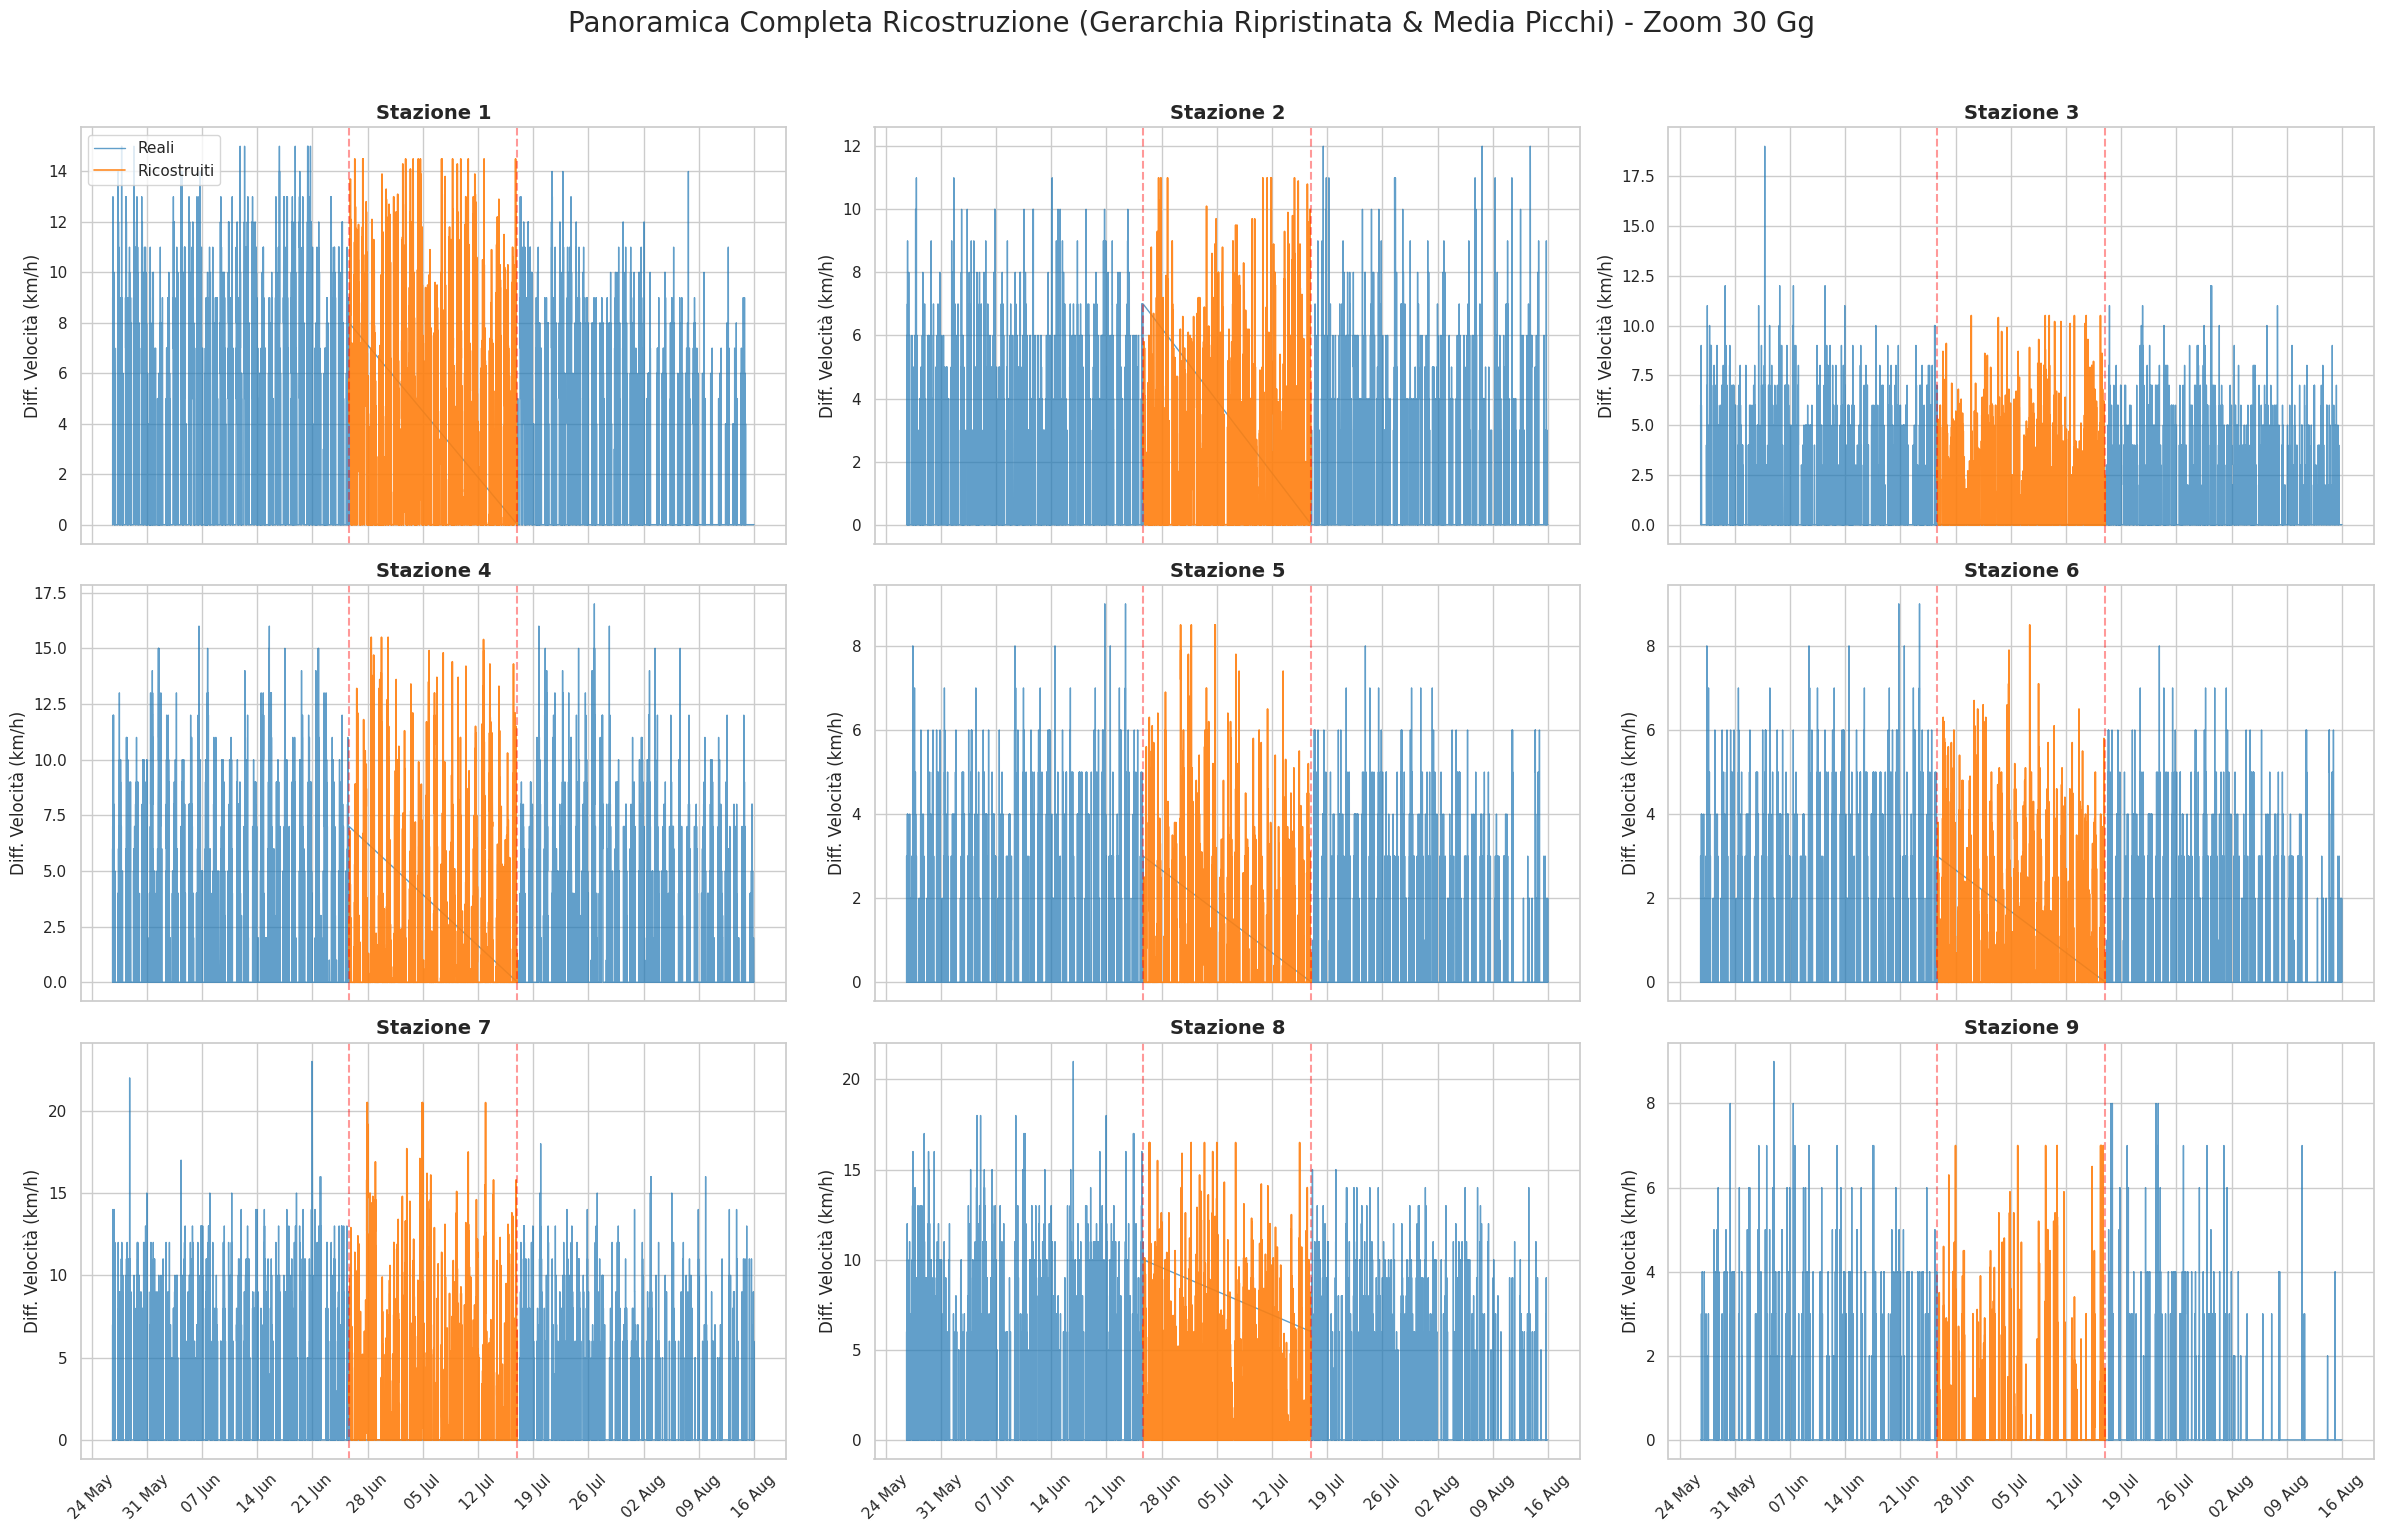

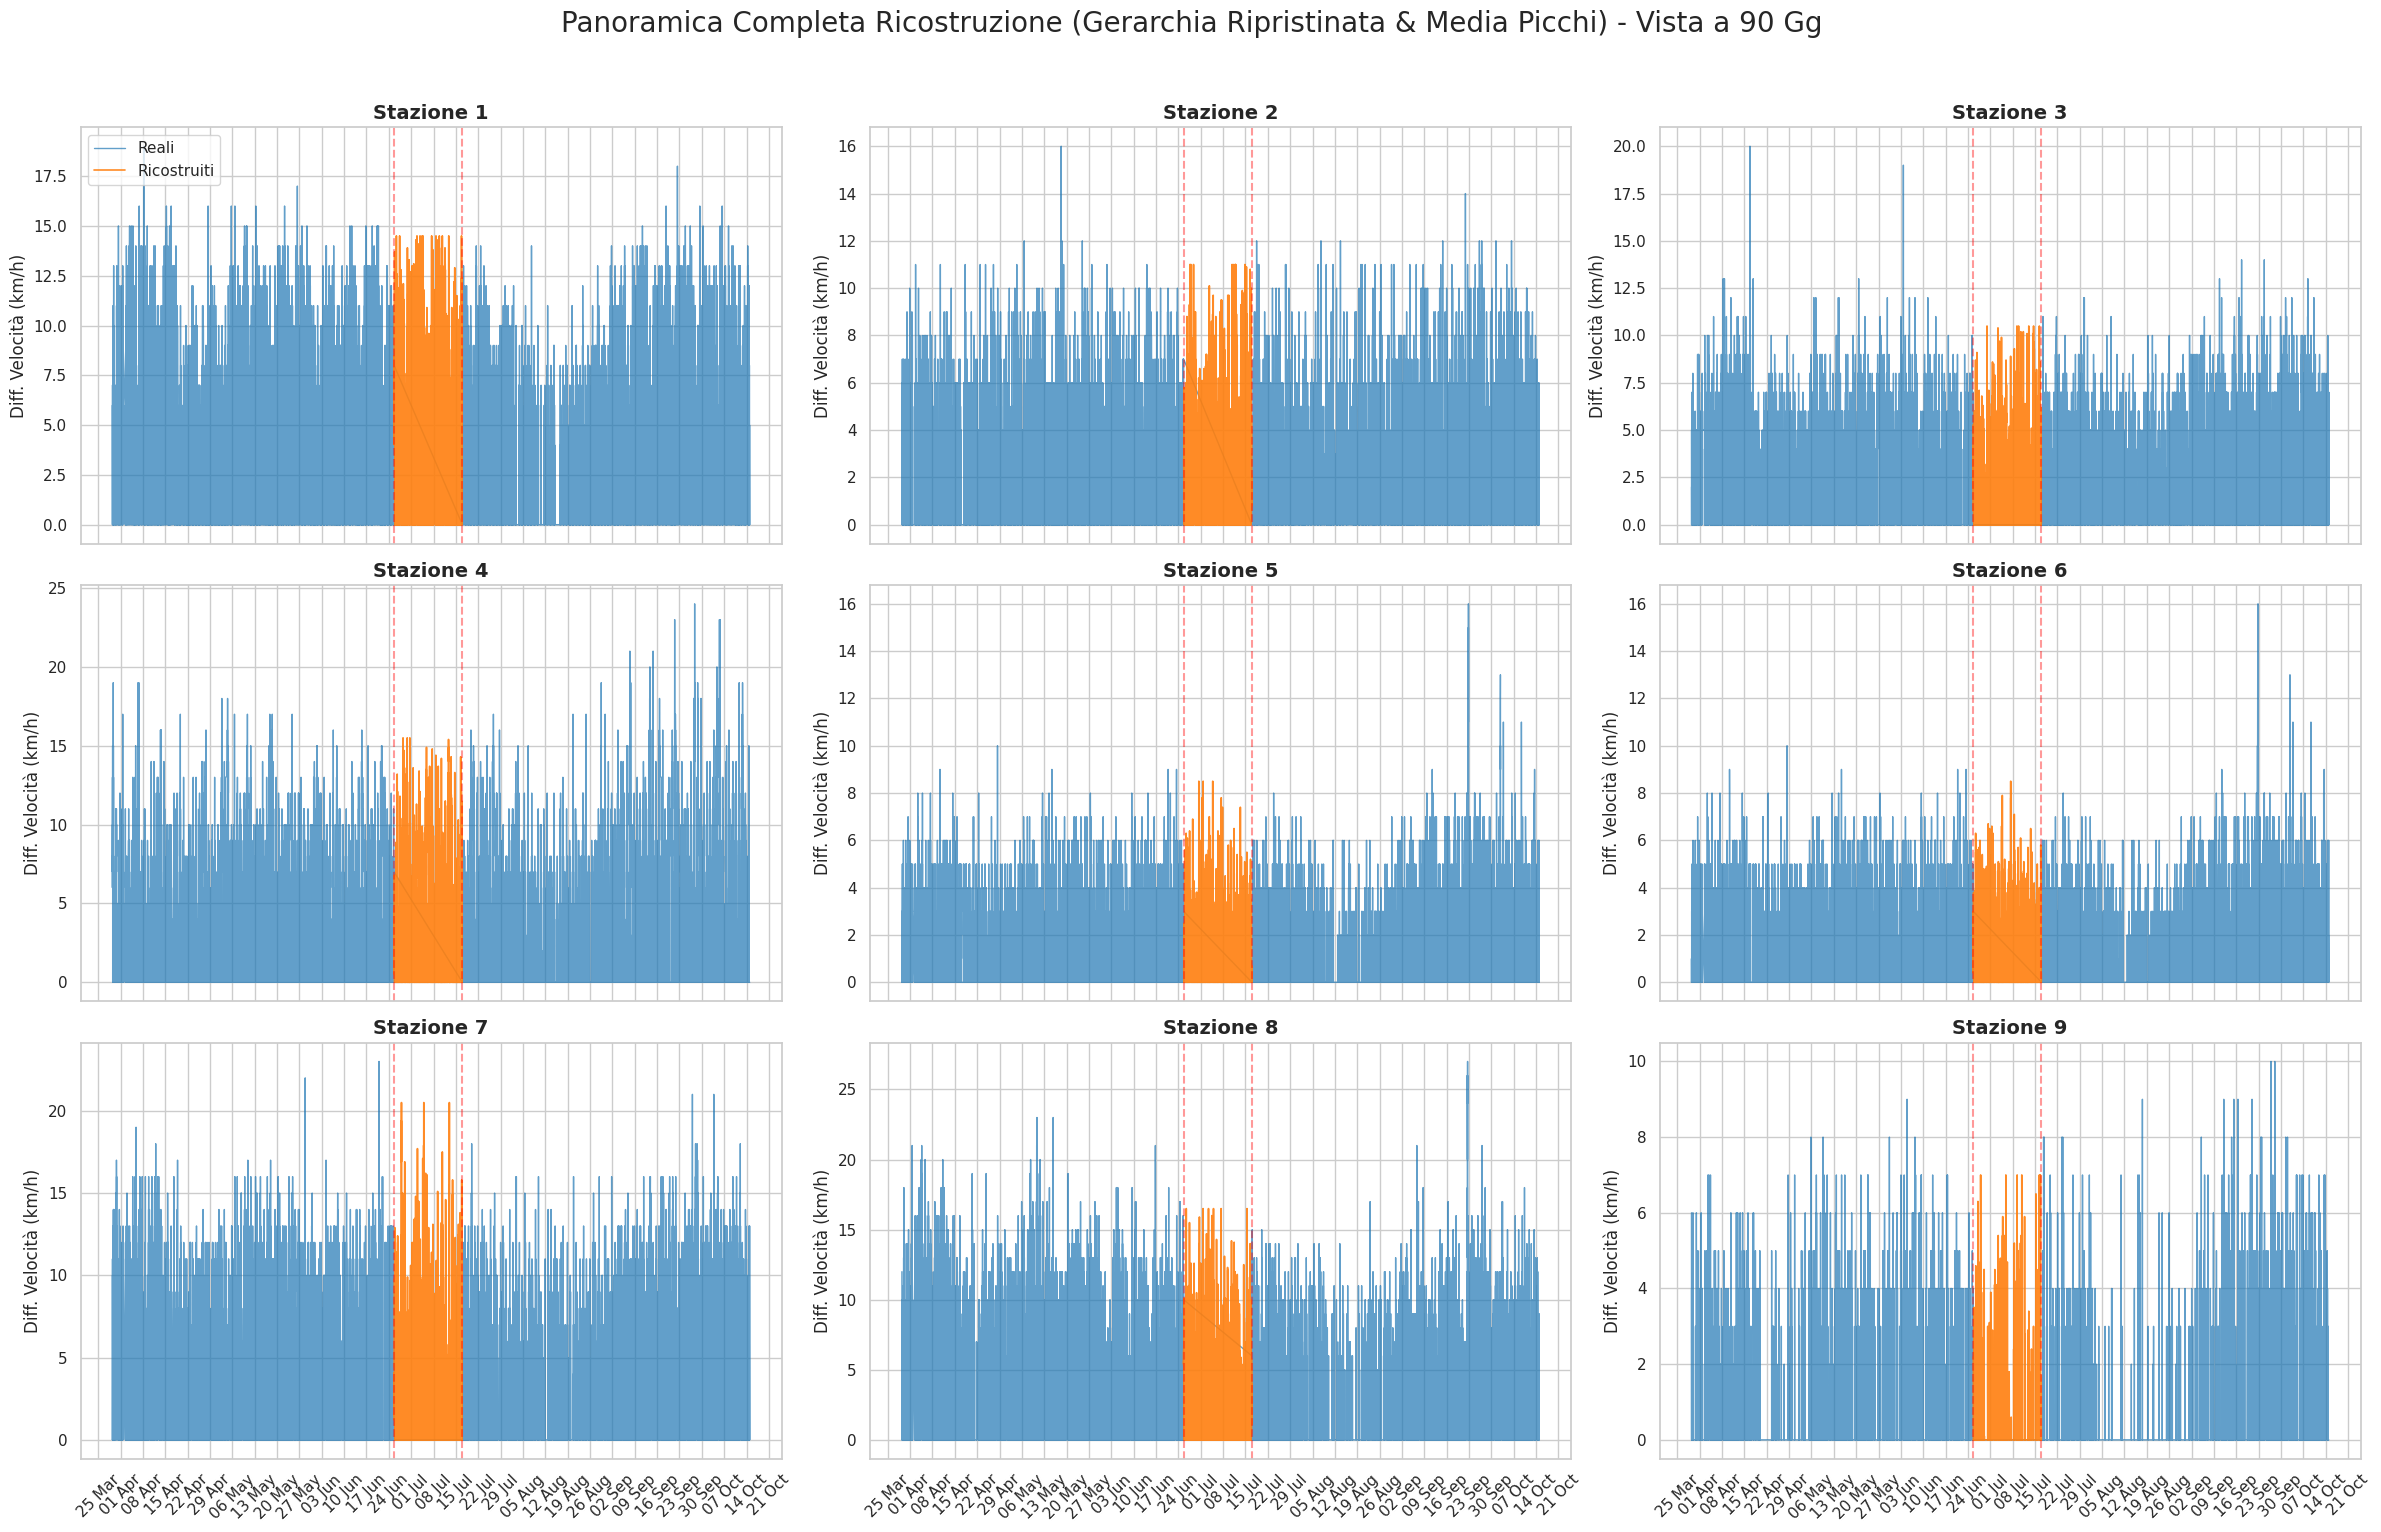

In [41]:
# ==========================================
# 4. SALVATAGGIO E GRAFICI
# ==========================================
df_reconstructed = pd.concat(all_reconstructed, ignore_index=True)
df_clean = df[~((df['timestamp'] >= gap_start) & (df['timestamp'] <= gap_end))].copy()
df_final = pd.concat([df_clean[['timestamp', 'id_stazione', 'differenza']], df_reconstructed], ignore_index=True)
df_final = df_final.sort_values(['id_stazione', 'timestamp']).reset_index(drop=True)

df_final['differenza'] = df_final['differenza'].clip(lower=0).round(1)

print(f"\nRicostruzione Completata! Punti imputati: {len(df_reconstructed)}")

nome_file_output = '/content/drive/MyDrive/Colab Notebooks/TIROCINIO/dataset_ricostruito/traffico_r2.csv'
df_final.to_csv(nome_file_output, index=False)
print(f"Dati salvati in: '{nome_file_output}'\n")

# ---- PLOT A 30 GIORNI ----
sns.set_theme(style="whitegrid")
num_stazioni = len(stazioni)
cols = 3
rows = int(np.ceil(num_stazioni / cols))
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(24, 5 * rows), sharex=True)
axes = np.array(axes).flatten()

plot_start = gap_start - pd.Timedelta(days=30)
plot_end = gap_end + pd.Timedelta(days=30)

for i, st in enumerate(stazioni):
    ax = axes[i]
    df_st = df_final[(df_final['id_stazione'] == st) & (df_final['timestamp'] >= plot_start) & (df_final['timestamp'] <= plot_end)].copy()
    mask_rec = (df_st['timestamp'] >= gap_start) & (df_st['timestamp'] <= gap_end)

    ax.plot(df_st[~mask_rec]['timestamp'], df_st[~mask_rec]['differenza'], label='Reali', color='#1f77b4', linewidth=1, alpha=0.7)
    ax.plot(df_st[mask_rec]['timestamp'], df_st[mask_rec]['differenza'], label='Ricostruiti', color='#ff7f0e', linewidth=1.2, alpha=0.9)

    ax.axvline(gap_start, color='red', linestyle='--', alpha=0.4)
    ax.axvline(gap_end, color='red', linestyle='--', alpha=0.4)
    ax.set_title(f'Stazione {st}', fontsize=14, fontweight='bold')
    ax.set_ylabel('Diff. Velocità (km/h)')
    if i == 0: ax.legend(loc='upper left')

for i in range(num_stazioni):
    if i >= num_stazioni - cols:
        axes[i].xaxis.set_major_locator(mdates.DayLocator(interval=7))
        axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
        plt.setp(axes[i].get_xticklabels(), rotation=45)

for j in range(i + 1, len(axes)): fig.delaxes(axes[j])
plt.suptitle('Panoramica Completa Ricostruzione (Gerarchia Ripristinata & Media Picchi) - Zoom 30 Gg', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

# ---- PLOT A 90 GIORNI ----
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(24, 5 * rows), sharex=True)
axes = np.array(axes).flatten()

plot_start = gap_start - pd.Timedelta(days=90)
plot_end = gap_end + pd.Timedelta(days=90)

for i, st in enumerate(stazioni):
    ax = axes[i]
    df_st = df_final[(df_final['id_stazione'] == st) & (df_final['timestamp'] >= plot_start) & (df_final['timestamp'] <= plot_end)].copy()
    mask_rec = (df_st['timestamp'] >= gap_start) & (df_st['timestamp'] <= gap_end)

    ax.plot(df_st[~mask_rec]['timestamp'], df_st[~mask_rec]['differenza'], label='Reali', color='#1f77b4', linewidth=1, alpha=0.7)
    ax.plot(df_st[mask_rec]['timestamp'], df_st[mask_rec]['differenza'], label='Ricostruiti', color='#ff7f0e', linewidth=1.2, alpha=0.9)

    ax.axvline(gap_start, color='red', linestyle='--', alpha=0.4)
    ax.axvline(gap_end, color='red', linestyle='--', alpha=0.4)
    ax.set_title(f'Stazione {st}', fontsize=14, fontweight='bold')
    ax.set_ylabel('Diff. Velocità (km/h)')
    if i == 0: ax.legend(loc='upper left')

for i in range(num_stazioni):
    if i >= num_stazioni - cols:
        axes[i].xaxis.set_major_locator(mdates.DayLocator(interval=7))
        axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
        plt.setp(axes[i].get_xticklabels(), rotation=45)

for j in range(i + 1, len(axes)): fig.delaxes(axes[j])
plt.suptitle('Panoramica Completa Ricostruzione (Gerarchia Ripristinata & Media Picchi) - Vista a 90 Gg', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

## 5. Validazione Statistica: Contesto Macro vs Contesto Micro
Per dimostrare l'accuratezza del modello rispetto ai cali fisiologici di traffico e alla preservazione del pattern giornaliero, si implementa una dashboard analitica per stazione (2x2).
Si calcolano metriche come l'Errore Relativo e la Correlazione di Pearson (Shape Similarity) mettendo a confronto il dato generato (Luglio) con il **Macro-Contesto** (intero mese di Giugno) e il **Micro-Contesto** (la settimana di traffico precedente e successiva al gap). Questo permette di valutare quantitativamente come l'algoritmo si agganci alla reale temperatura di traffico estivo isolandola dai volumi invernali.

Esecuzione della suite di validazione avanzata...



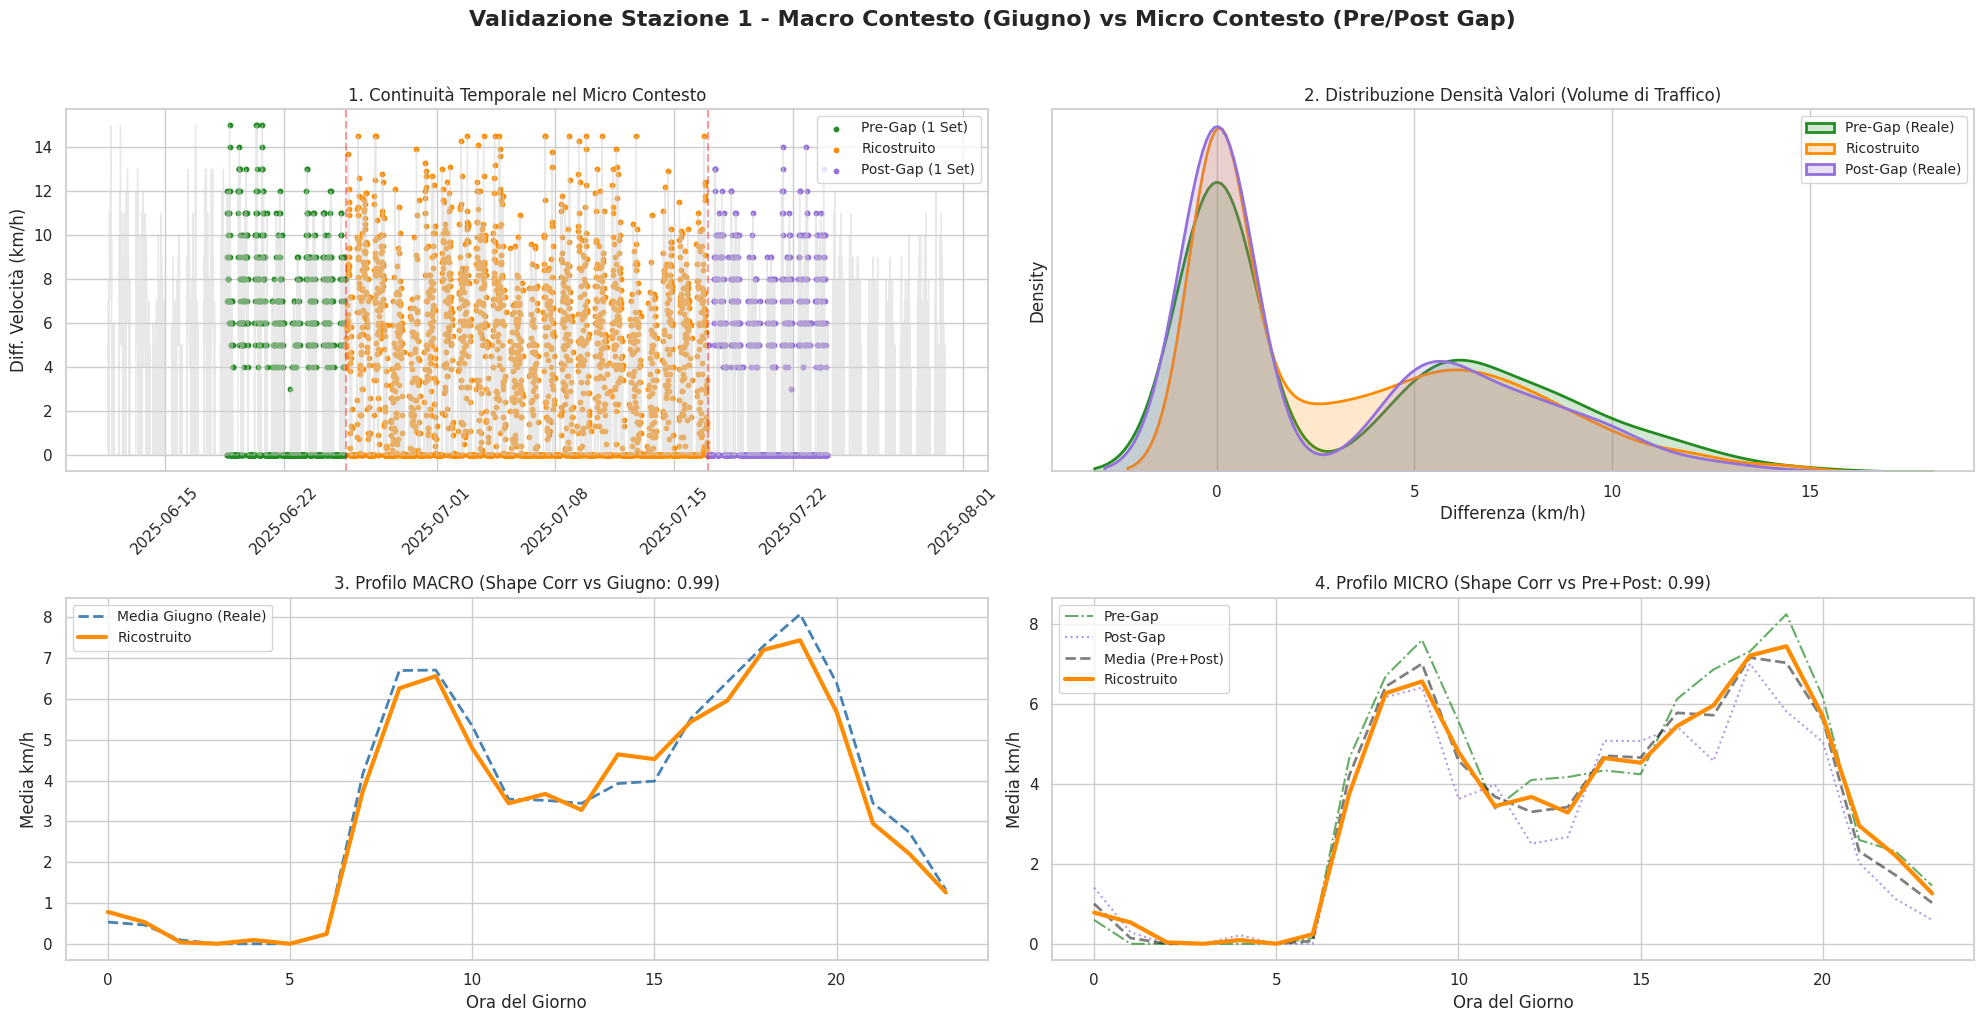

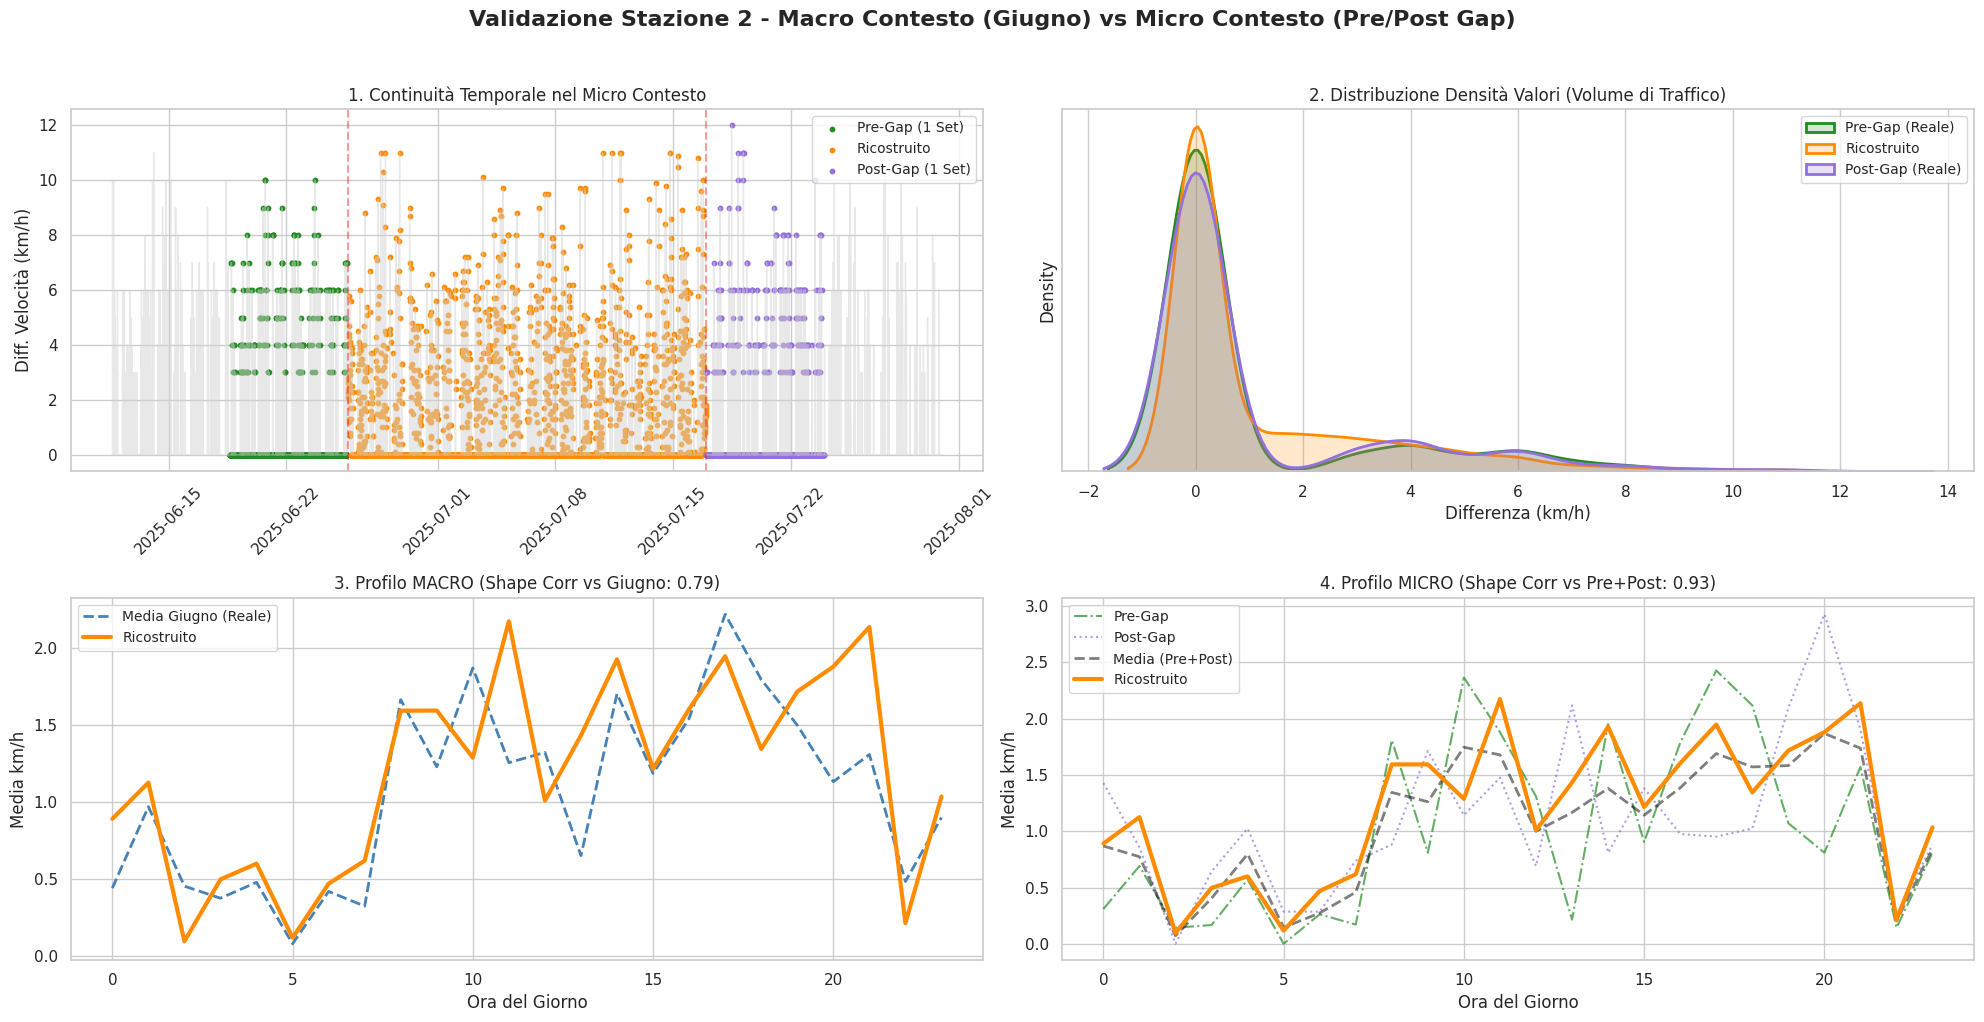

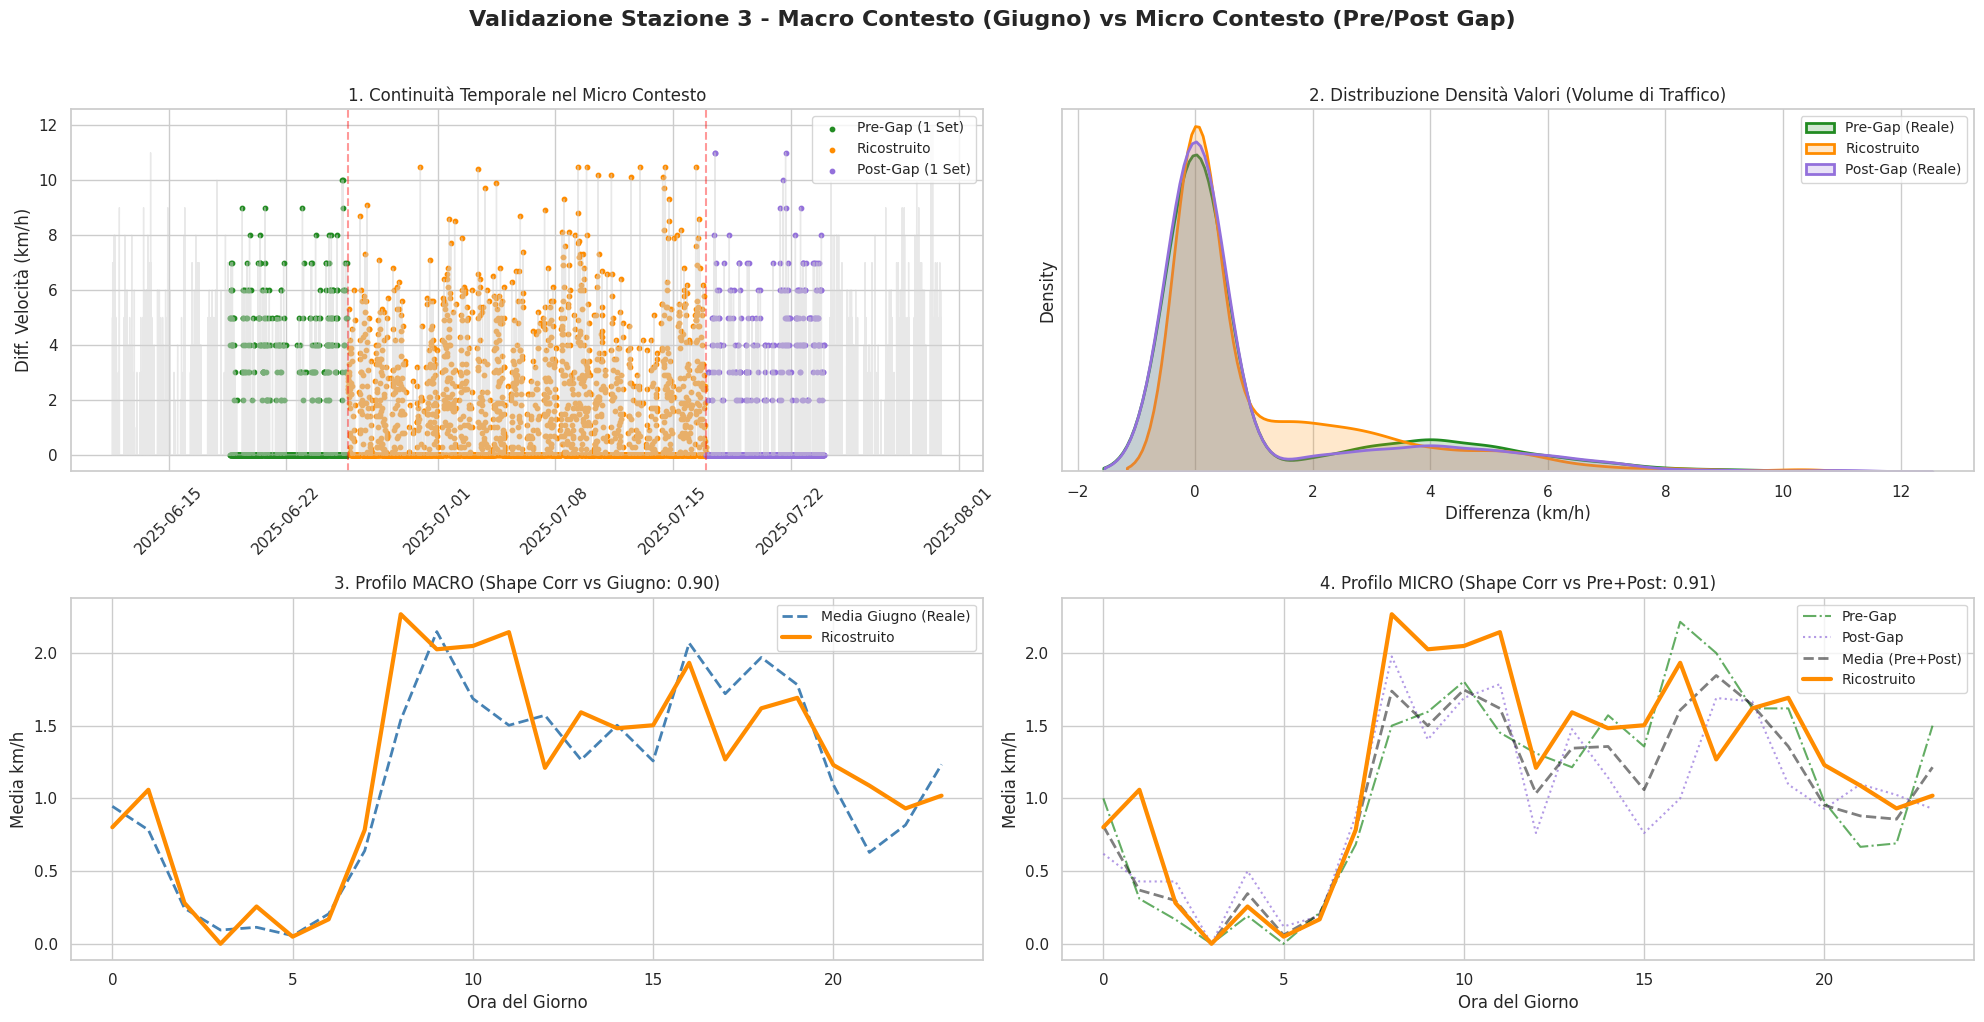

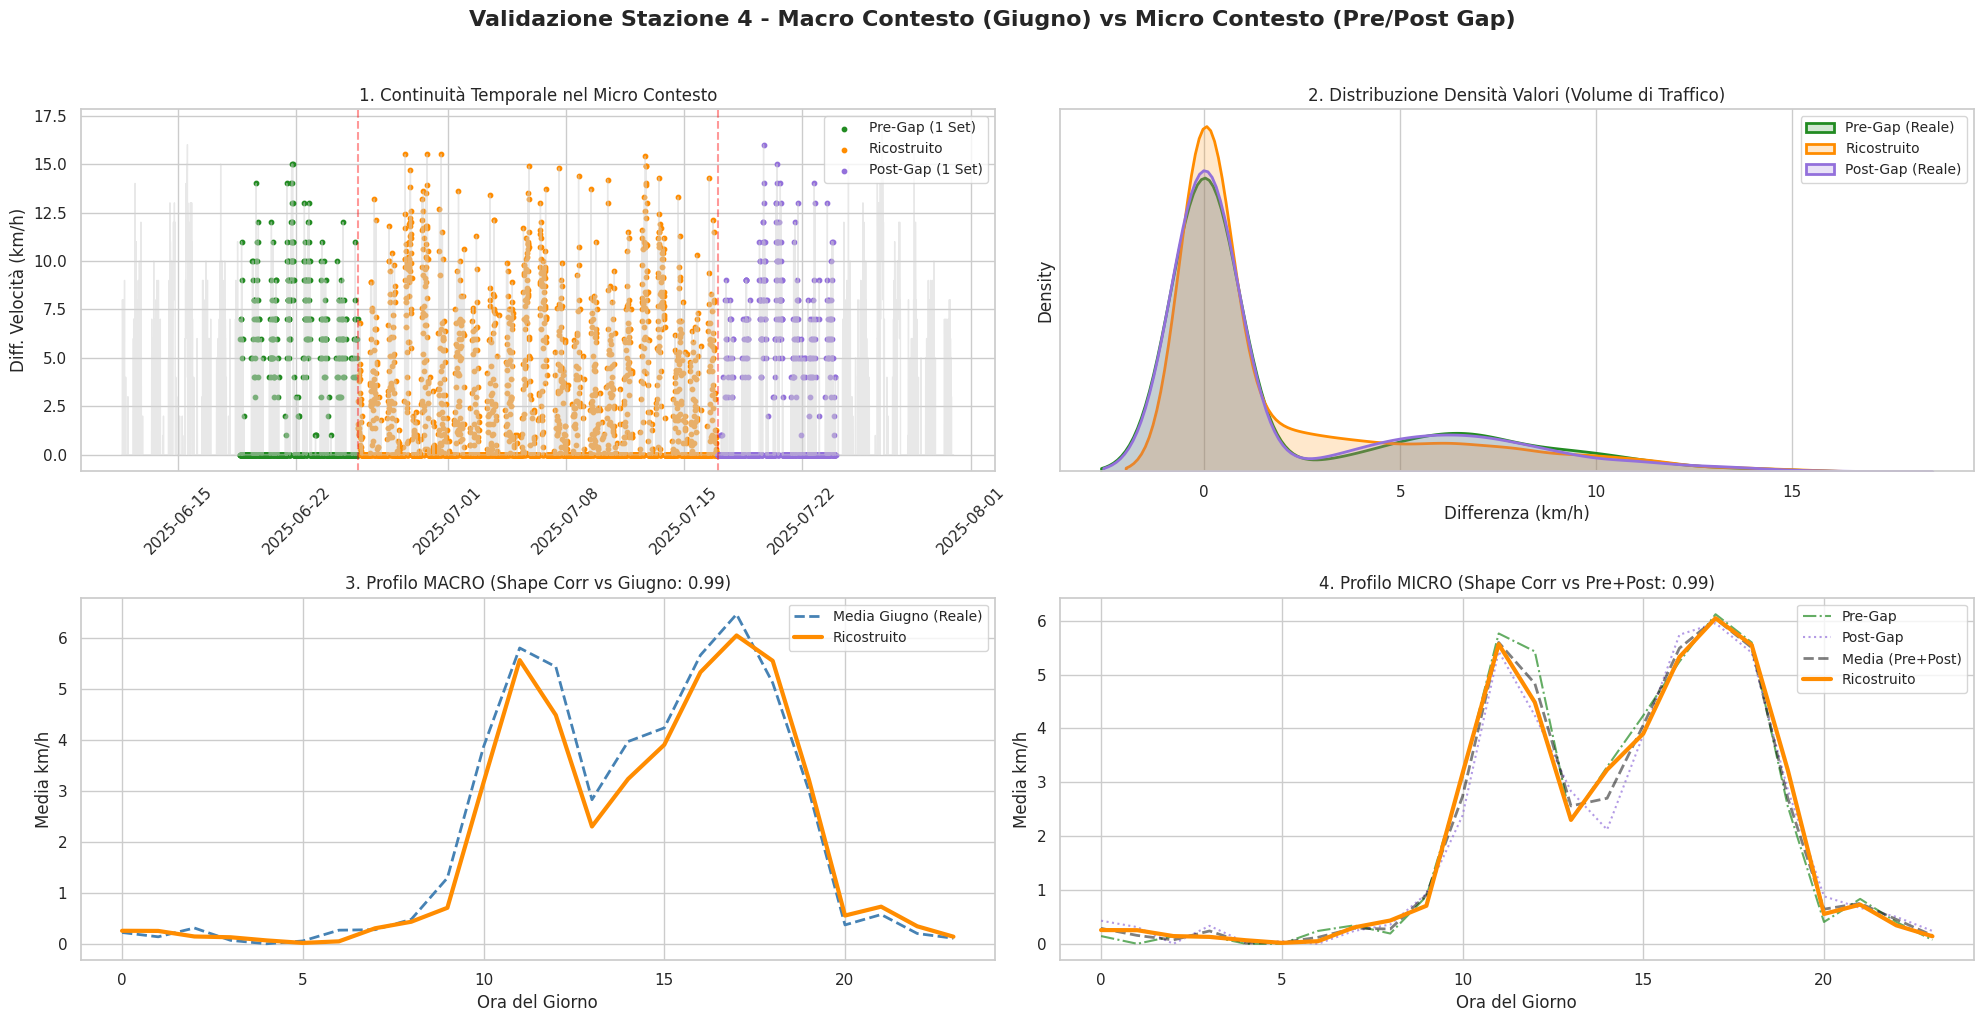

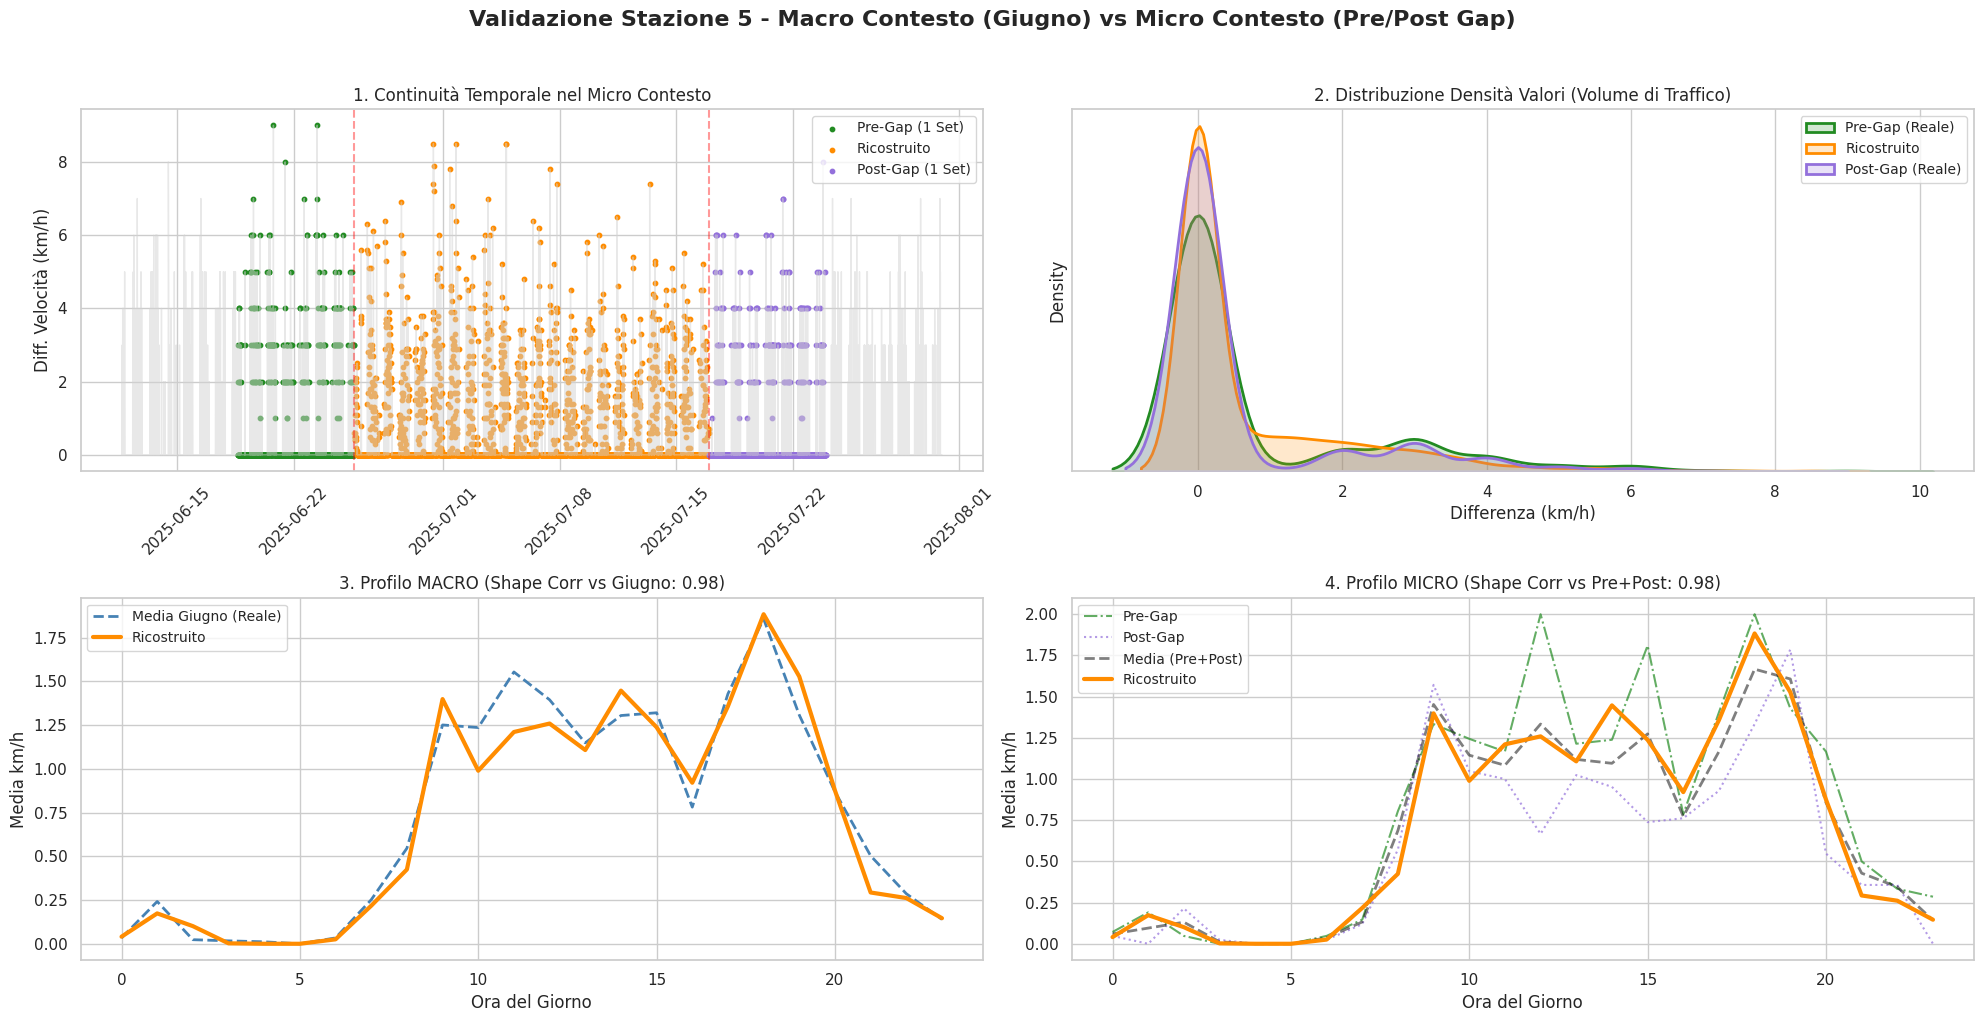

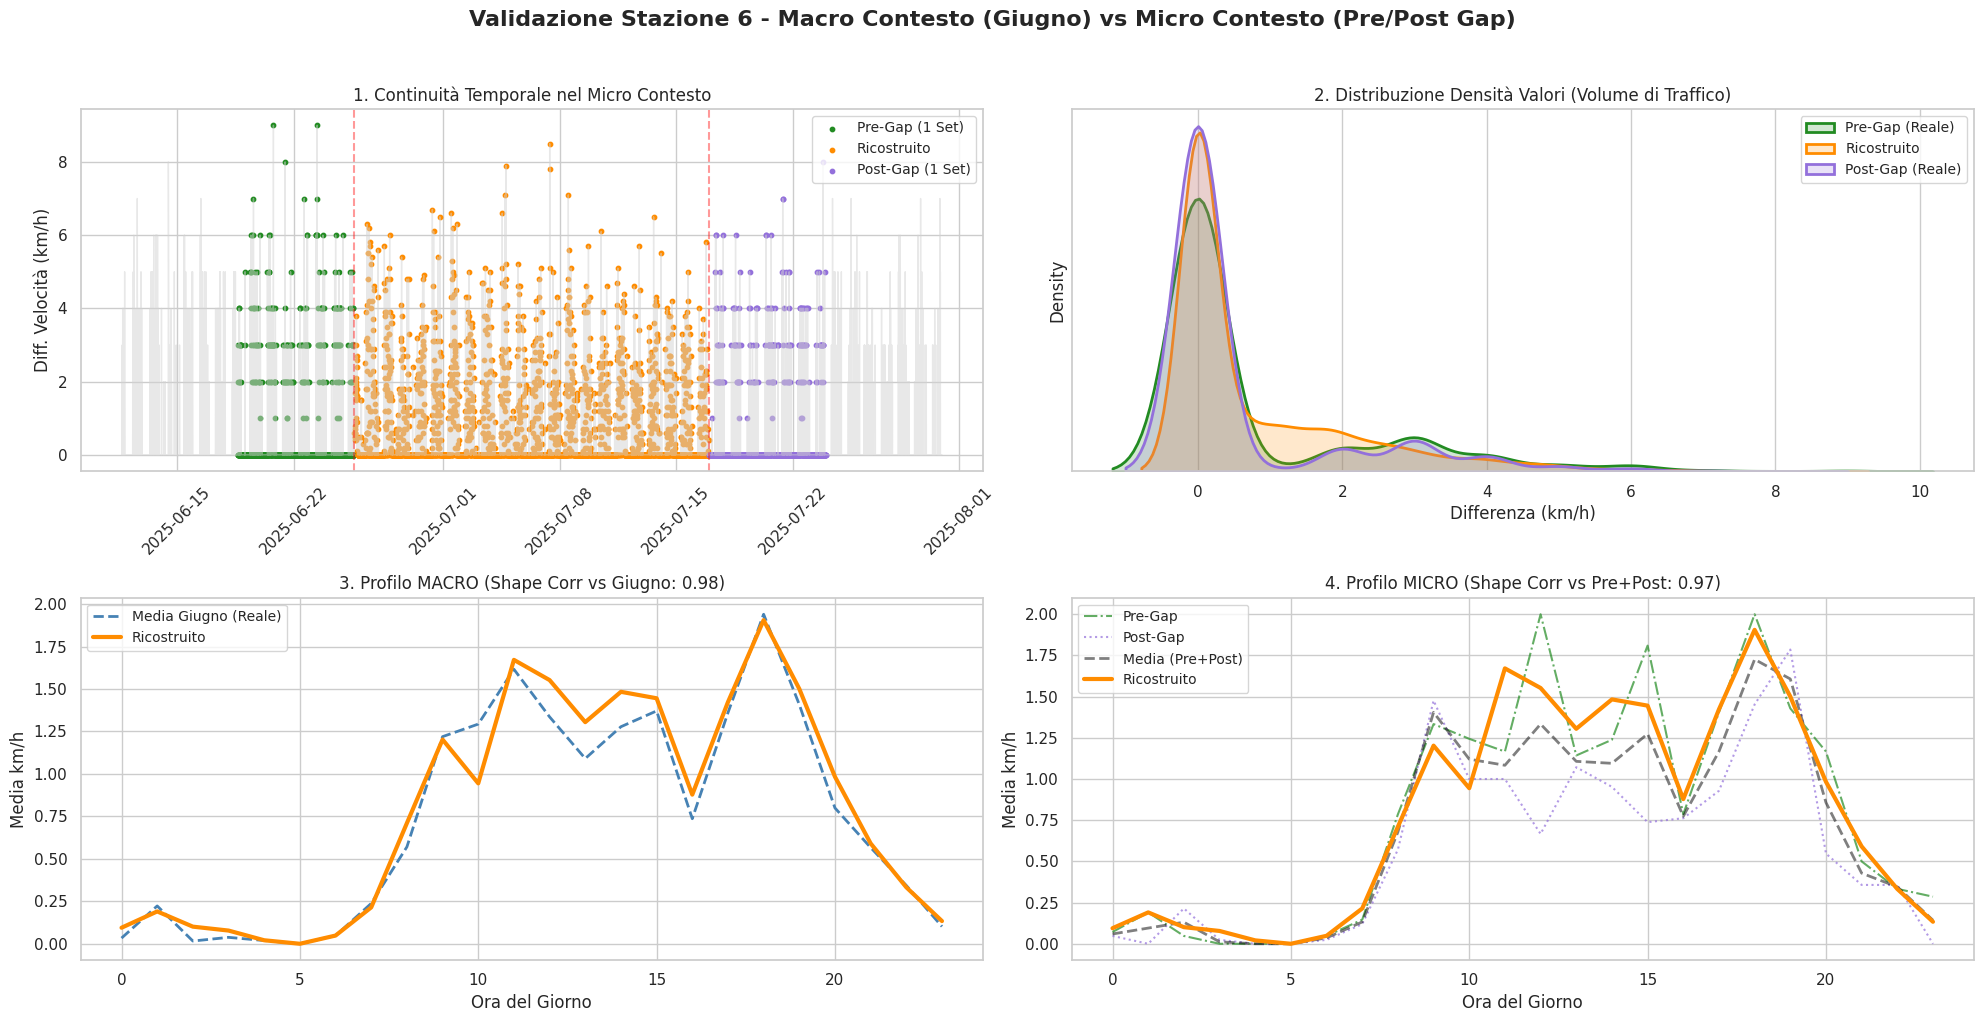

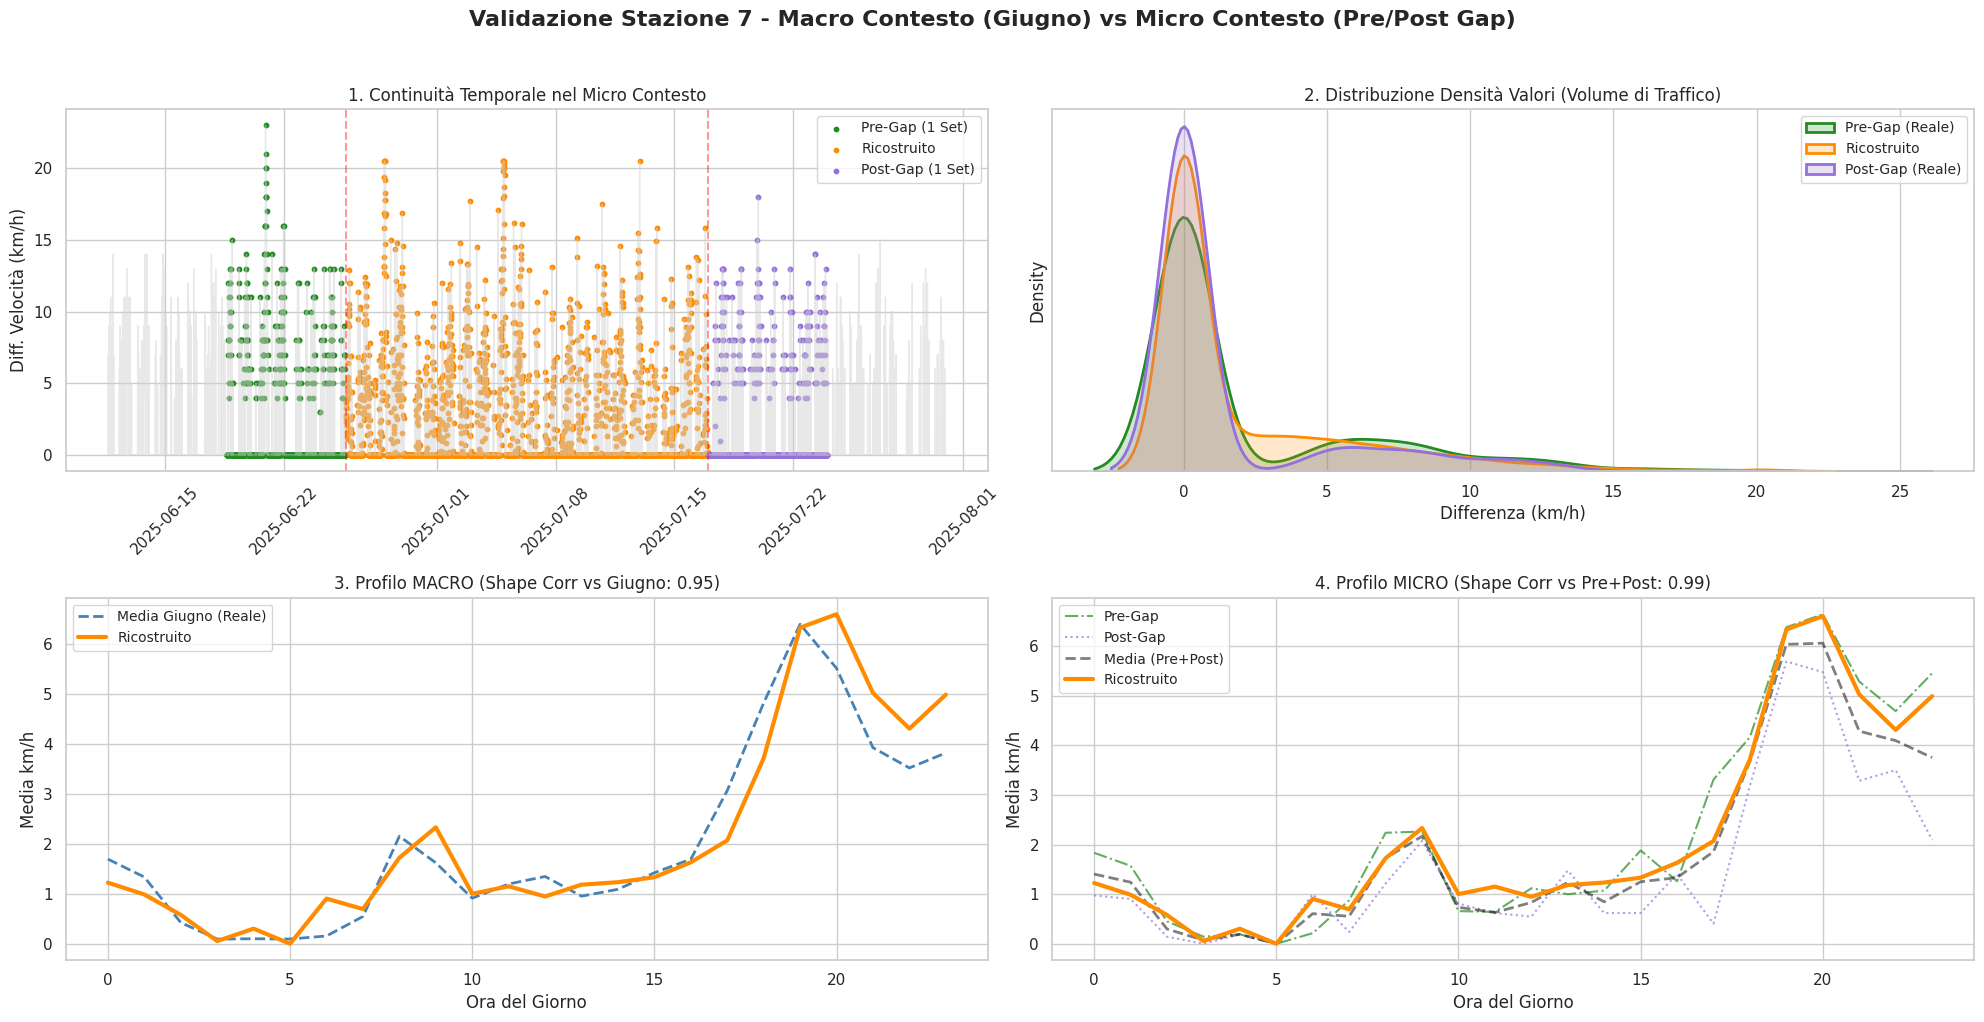

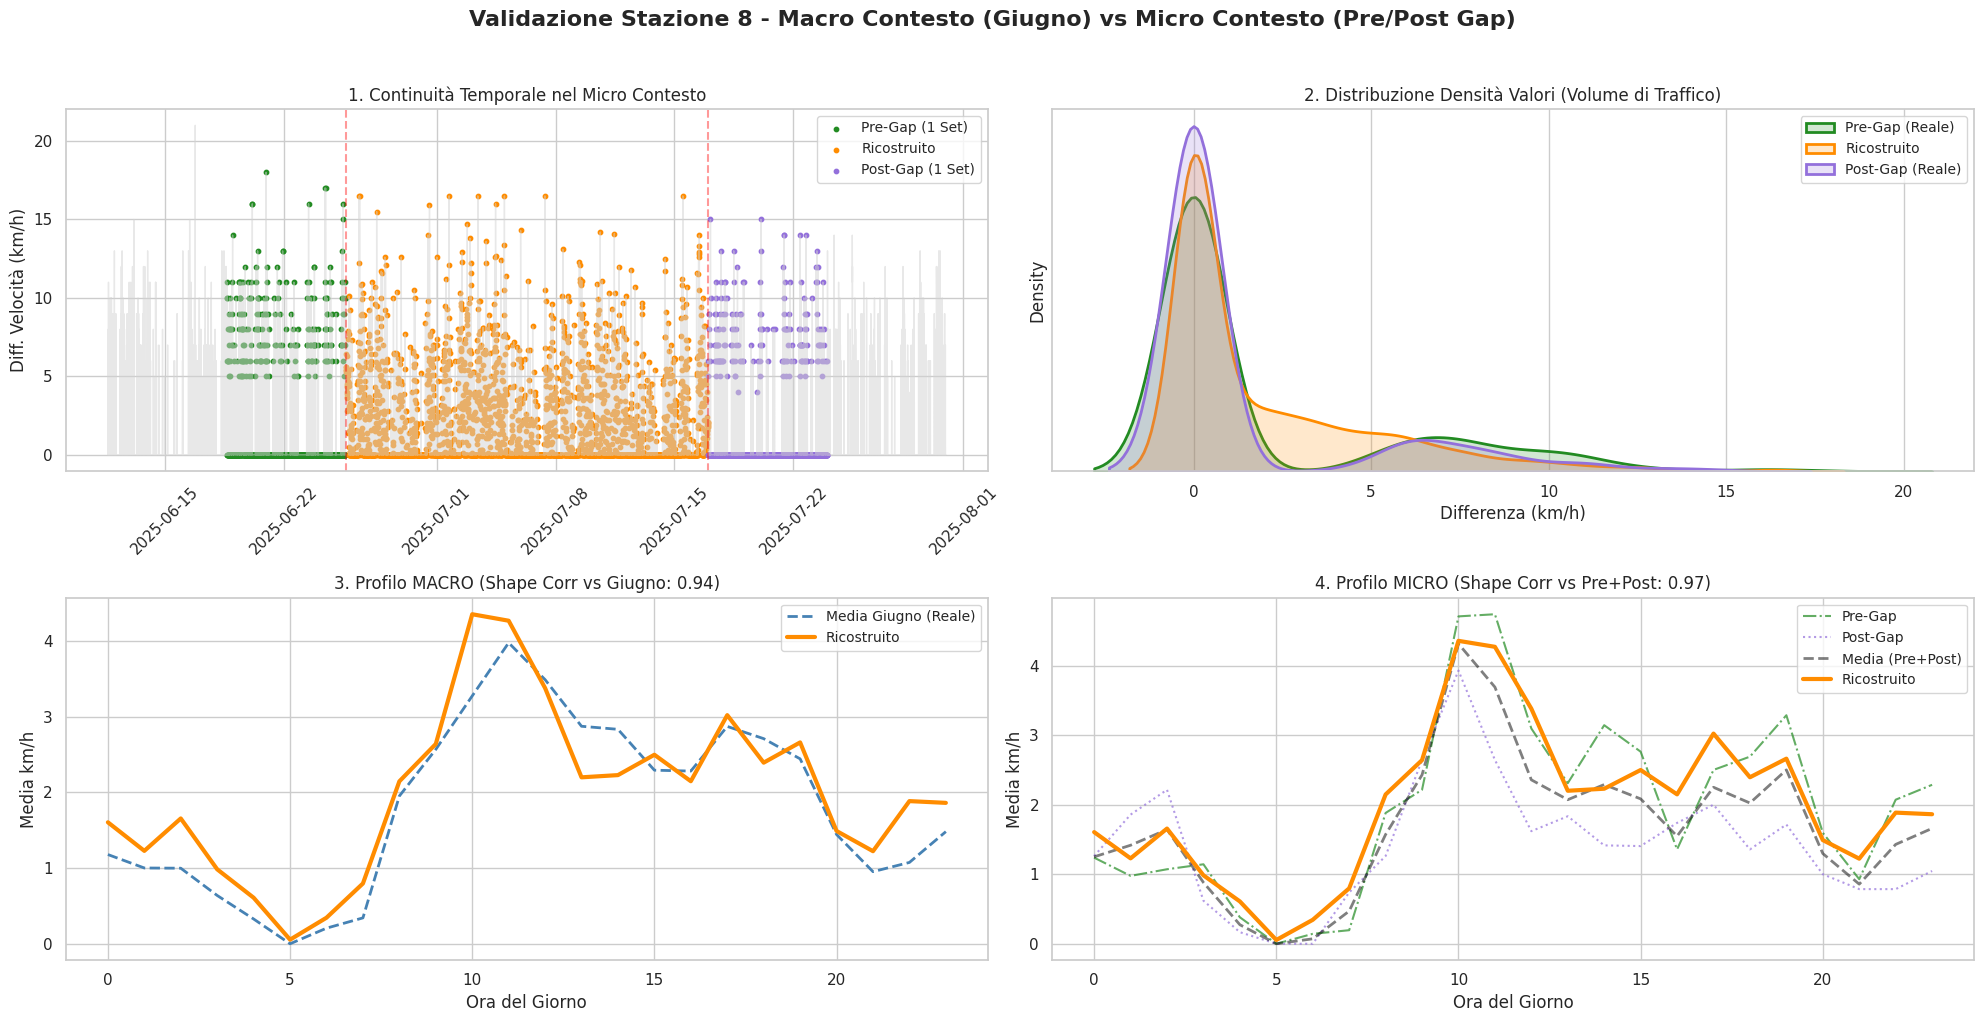

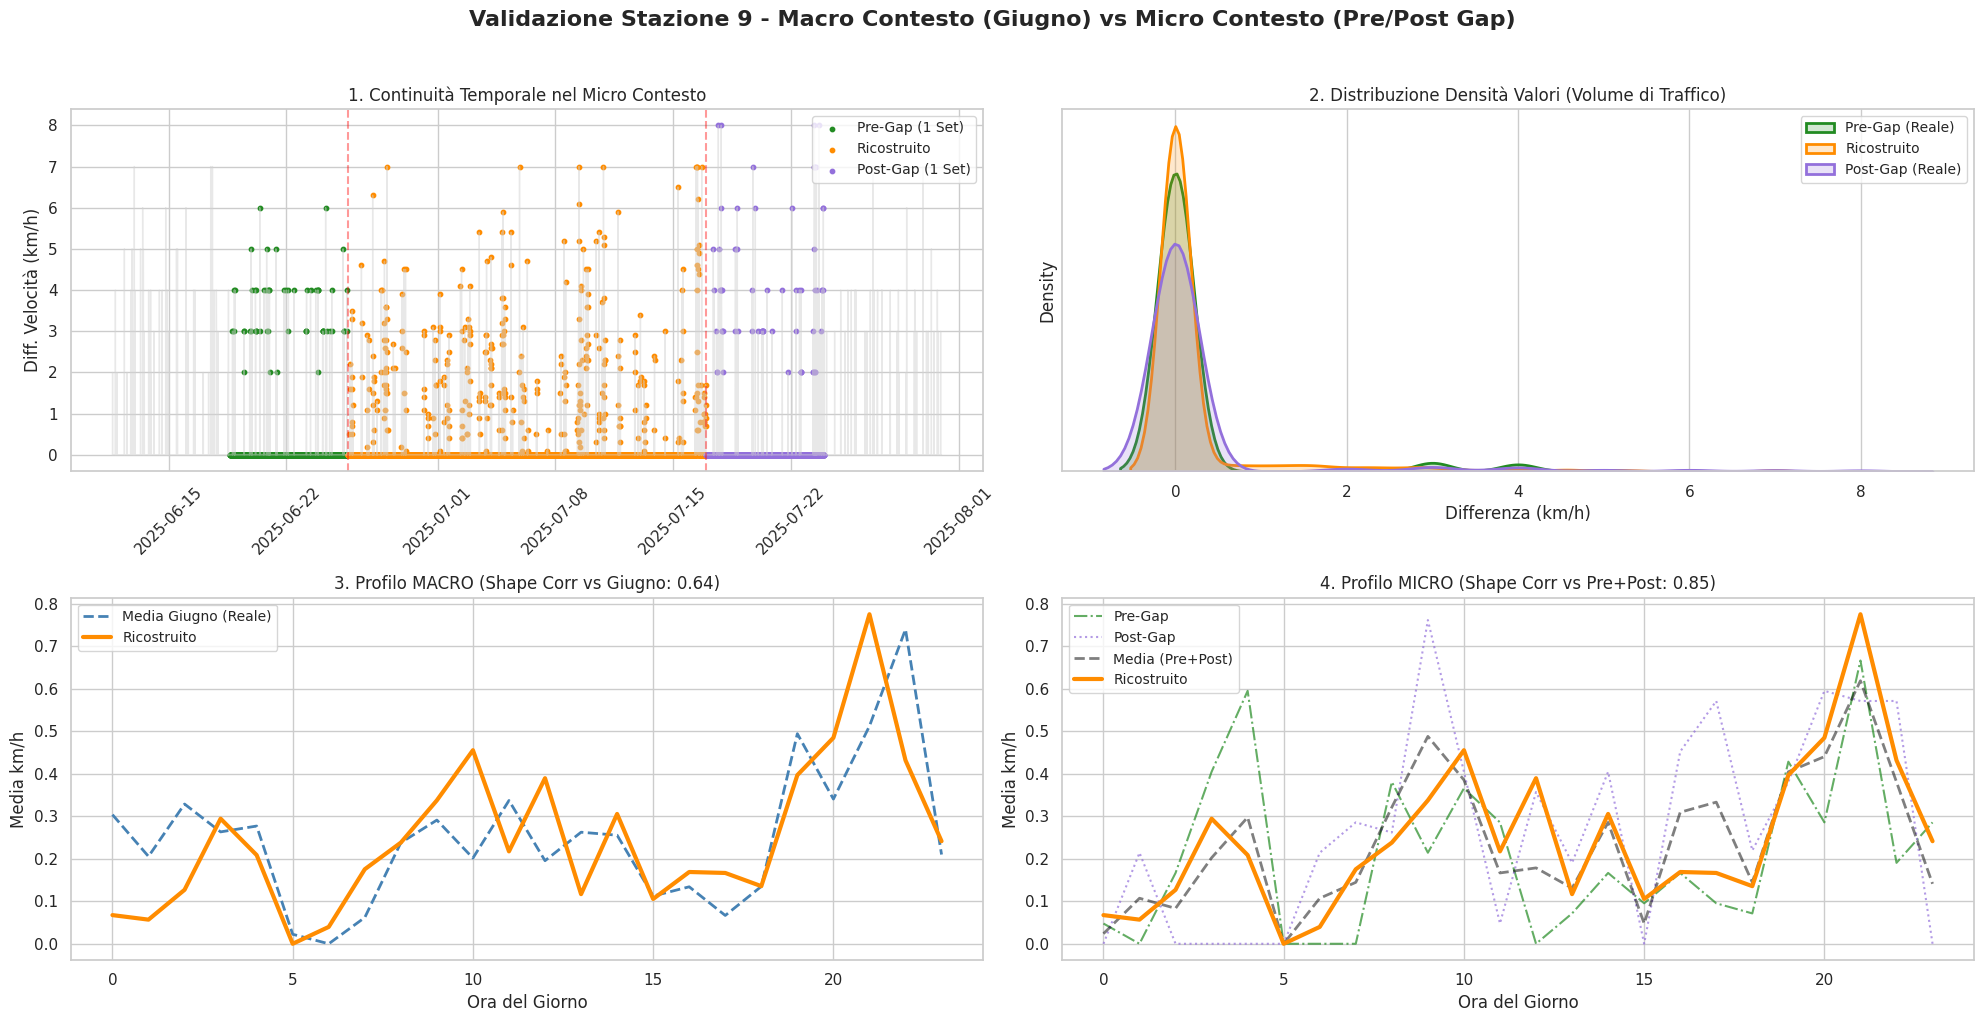


SCORE CARD VALIDAZIONE: MACRO (Giugno) vs MICRO (Pre+Post)


,Stazione,Media Ricostruita,Target MACRO (Giugno),Target MICRO (Pre+Post),Err % (vs Giugno),Err % (vs Micro),Corr (vs Giugno),Corr (vs Micro)
0,1,3.4,3.5,3.3,3.7,1.4,0.992,0.994
1,2,1.2,1.1,1.1,12.7,12.3,0.785,0.935
2,3,1.2,1.1,1.0,5.9,15.5,0.901,0.914
3,4,2.0,2.1,1.9,7.5,0.7,0.990,0.995
4,5,0.7,0.7,0.7,3.6,1.5,0.978,0.978
5,6,0.8,0.7,0.7,6.6,13.2,0.984,0.966
6,7,2.1,2.0,1.9,5.0,12.2,0.952,0.990
7,8,2.0,1.8,1.7,10.3,18.1,0.940,0.969
8,9,0.2,0.2,0.2,0.9,3.4,0.643,0.853


In [42]:
# ==============================================================================
# 5. VALIDAZIONE STATISTICA MACRO (Giugno) E MICRO (Settimane Adiacenti)
# ==============================================================================
print("Esecuzione della suite di validazione avanzata...\n")

# Definiamo le finestre temporali esatte (1 Settimana)
pre_start = gap_start - pd.Timedelta(days=7)
post_end = gap_end + pd.Timedelta(days=7)

validation_metrics = []

sns.set_theme(style="whitegrid")
stazioni = sorted(df_final['id_stazione'].unique())

for st in stazioni:
    df_st = df_final[df_final['id_stazione'] == st].copy()

    # --- 1. Creazione Maschere per i 4 Periodi di Riferimento ---
    m_june = df_st['timestamp'].dt.month == 6
    m_rec = (df_st['timestamp'] >= gap_start) & (df_st['timestamp'] <= gap_end)
    m_pre = (df_st['timestamp'] >= pre_start) & (df_st['timestamp'] < gap_start)
    m_post = (df_st['timestamp'] > gap_end) & (df_st['timestamp'] <= post_end)

    # Estrazione subset
    df_june = df_st[m_june]
    df_rec = df_st[m_rec]
    df_pre = df_st[m_pre]
    df_post = df_st[m_post]

    # Il Contesto Locale complessivo è la fusione tra Pre e Post
    df_local = pd.concat([df_pre, df_post])

    # --- 2. Calcolo Profili Orari Medi ---
    def get_hourly_profile(df_subset):
        if df_subset.empty: return pd.Series(np.nan, index=np.arange(24))
        return df_subset.groupby(df_subset['timestamp'].dt.hour)['differenza'].mean()

    prof_june = get_hourly_profile(df_june)
    prof_rec = get_hourly_profile(df_rec)
    prof_pre = get_hourly_profile(df_pre)
    prof_post = get_hourly_profile(df_post)
    prof_local = get_hourly_profile(df_local) # Profilo medio delle due settimane reali adiacenti

    # --- 3. Calcolo Metriche Statistiche ---
    mean_june = prof_june.mean()
    mean_rec = prof_rec.mean()
    mean_local = prof_local.mean()

    # Errore Relativo %
    err_rel_june = abs(mean_rec - mean_june) / mean_june * 100 if mean_june > 0 and not pd.isna(mean_rec) else 0.0
    err_rel_local = abs(mean_rec - mean_local) / mean_local * 100 if mean_local > 0 and not pd.isna(mean_rec) else 0.0

    # Correlazione di Pearson (Gestita per varianze zero)
    def calc_corr(p1, p2):
        corr = p1.corr(p2)
        if pd.isna(corr):
            return 1.0 if p1.std() == 0 and p2.std() == 0 else 0.0
        return corr

    corr_june = calc_corr(prof_rec, prof_june)
    corr_local = calc_corr(prof_rec, prof_local)

    validation_metrics.append({
        'Stazione': st,
        'Media Ricostruita': mean_rec,
        'Target MACRO (Giugno)': mean_june,
        'Target MICRO (Pre+Post)': mean_local,
        'Err % (vs Giugno)': err_rel_june,
        'Err % (vs Micro)': err_rel_local,
        'Corr (vs Giugno)': corr_june,
        'Corr (vs Micro)': corr_local
    })

    # --- 4. PLOTTING DASHBOARD 2x2 ---
    fig = plt.figure(figsize=(20, 10))
    gs = fig.add_gridspec(2, 2)
    fig.suptitle(f"Validazione Stazione {st} - Macro Contesto (Giugno) vs Micro Contesto (Pre/Post Gap)", fontsize=16, fontweight='bold', y=1.02)

    # Plot 1: Zoom Temporale (Pre, Gap, Post)
    ax1 = fig.add_subplot(gs[0, 0])
    # Dati di sfondo per dare contesto visivo (14 gg prima e dopo)
    bg_start = pre_start - pd.Timedelta(days=7)
    bg_end = post_end + pd.Timedelta(days=7)
    ax1.plot(df_st[(df_st['timestamp'] >= bg_start) & (df_st['timestamp'] <= bg_end)]['timestamp'],
             df_st[(df_st['timestamp'] >= bg_start) & (df_st['timestamp'] <= bg_end)]['differenza'],
             color='lightgray', linewidth=1, alpha=0.5)

    ax1.scatter(df_pre['timestamp'], df_pre['differenza'], color='forestgreen', s=10, label='Pre-Gap (1 Set)')
    ax1.scatter(df_rec['timestamp'], df_rec['differenza'], color='darkorange', s=10, label='Ricostruito')
    ax1.scatter(df_post['timestamp'], df_post['differenza'], color='mediumpurple', s=10, label='Post-Gap (1 Set)')

    ax1.axvline(gap_start, color='red', linestyle='--', alpha=0.4)
    ax1.axvline(gap_end, color='red', linestyle='--', alpha=0.4)
    ax1.set_title("1. Continuità Temporale nel Micro Contesto")
    ax1.tick_params(axis='x', rotation=45)
    ax1.legend(loc='upper right', fontsize='small')
    ax1.set_ylabel("Diff. Velocità (km/h)")

    # Plot 2: Distribuzione Densità Valori (KDE) - Focus su Pre/Post/Ricostruito
    ax2 = fig.add_subplot(gs[0, 1])
    datasets = [('Pre-Gap (Reale)', df_pre['differenza'], 'forestgreen'),
                ('Ricostruito', df_rec['differenza'], 'darkorange'),
                ('Post-Gap (Reale)', df_post['differenza'], 'mediumpurple')]

    for label, data, color in datasets:
        data = data.dropna()
        if len(data) > 1 and data.std() > 0:
            sns.kdeplot(data, ax=ax2, fill=True, label=label, color=color, alpha=0.2, linewidth=2)
        elif len(data) > 0:
            ax2.axvline(data.mean(), color=color, linestyle='--', label=f"{label} (Costante)")

    ax2.set_title("2. Distribuzione Densità Valori (Volume di Traffico)")
    ax2.set_xlabel("Differenza (km/h)")
    ax2.set_yticks([])
    ax2.legend(fontsize='small')

    # Plot 3: Profilo Orario (MACRO: Giugno vs Ricostruito)
    ax3 = fig.add_subplot(gs[1, 0])
    ax3.plot(prof_june.index, prof_june, label='Media Giugno (Reale)', color='steelblue', linewidth=2, linestyle='--')
    ax3.plot(prof_rec.index, prof_rec, label='Ricostruito', color='darkorange', linewidth=3)

    ax3.set_title(f"3. Profilo MACRO (Shape Corr vs Giugno: {corr_june:.2f})")
    ax3.set_xlabel("Ora del Giorno")
    ax3.set_ylabel("Media km/h")
    ax3.legend(fontsize='small')

    # Plot 4: Profilo Orario (MICRO: Pre vs Post vs Ricostruito)
    ax4 = fig.add_subplot(gs[1, 1])
    ax4.plot(prof_pre.index, prof_pre, label='Pre-Gap', color='forestgreen', linewidth=1.5, linestyle='-.', alpha=0.7)
    ax4.plot(prof_post.index, prof_post, label='Post-Gap', color='mediumpurple', linewidth=1.5, linestyle=':', alpha=0.7)

    # Creiamo una linea grigia tratteggiata per la media tra Pre e Post
    ax4.plot(prof_local.index, prof_local, label='Media (Pre+Post)', color='black', linewidth=2, linestyle='--', alpha=0.5)
    ax4.plot(prof_rec.index, prof_rec, label='Ricostruito', color='darkorange', linewidth=3)

    ax4.set_title(f"4. Profilo MICRO (Shape Corr vs Pre+Post: {corr_local:.2f})")
    ax4.set_xlabel("Ora del Giorno")
    ax4.set_ylabel("Media km/h")
    ax4.legend(fontsize='small')

    plt.tight_layout()
    plt.show()

# --- 5.3 Score Card Finale ---
print("\n" + "="*90)
print("SCORE CARD VALIDAZIONE: MACRO (Giugno) vs MICRO (Pre+Post)")
print("="*90)

df_metrics = pd.DataFrame(validation_metrics)
df_metrics_view = df_metrics.copy()

# Arrotondamenti per la tabella
for col in ['Media Ricostruita', 'Target MACRO (Giugno)', 'Target MICRO (Pre+Post)', 'Err % (vs Giugno)', 'Err % (vs Micro)']:
    df_metrics_view[col] = df_metrics_view[col].round(1)

df_metrics_view['Corr (vs Giugno)'] = df_metrics_view['Corr (vs Giugno)'].round(3)
df_metrics_view['Corr (vs Micro)'] = df_metrics_view['Corr (vs Micro)'].round(3)

from IPython.display import display
display(df_metrics_view)

## 6. Validazione Pattern e Matrice di Correlazione Mensile
L'ultimo passaggio analitico consolida i risultati offrendo una prospettiva a lungo termine (da Aprile a Dicembre). Attraverso la generazione di Boxplot multimensili e Matrici di Correlazione (Heatmaps), si osserva come il mese di Luglio ricostruito si posizioni fluidamente nell'andamento annuale. Si conclude calcolando la Distanza Euclidea tra i centroidi dei profili orari dei tre mesi centrali (Giugno, Luglio e Settembre).


 VALIDAZIONE COERENZA LUGLIO RICOSTRUITO (MACRO-ANALISI)

=== Analisi pattern per Stazione 1 ===


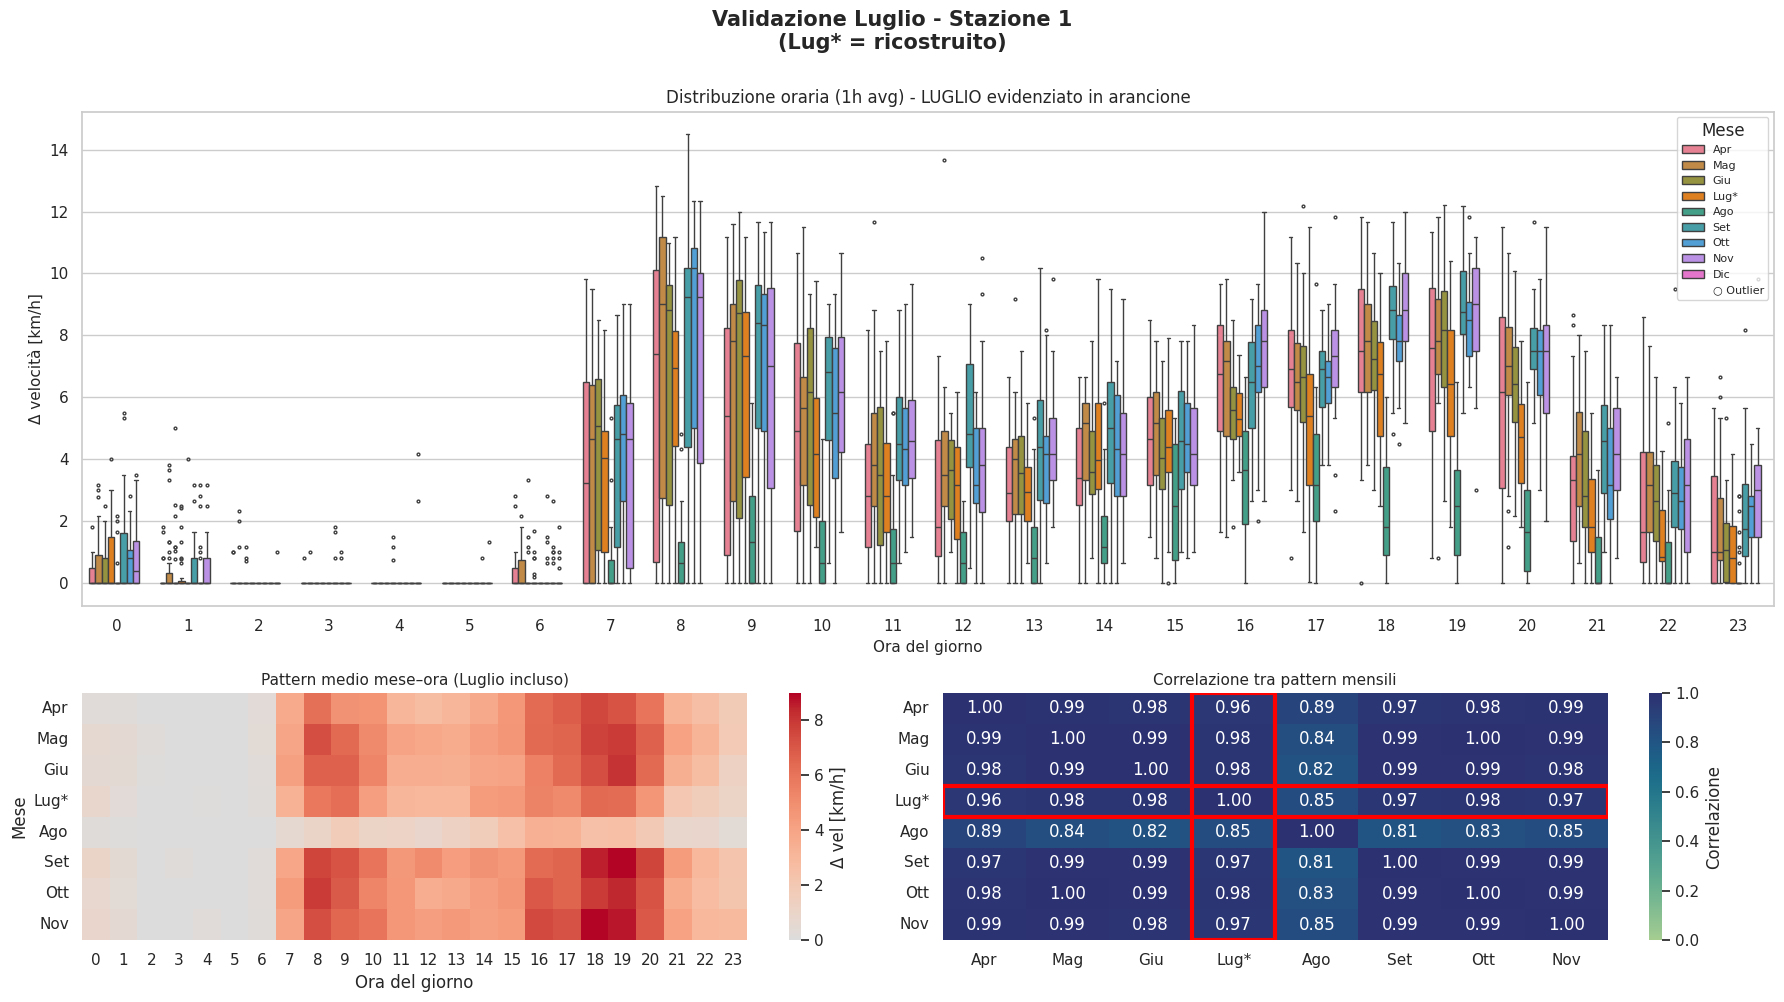


 Metriche di coerenza per Stazione 1:
  • Correlazione Luglio con altri mesi:
    ⭐ Apr: 0.964
    ⭐ Mag: 0.975
    ⭐ Giu: 0.976
    ⭐ Ago: 0.850
    ⭐ Set: 0.968
    ⭐ Ott: 0.979
    ⭐ Nov: 0.965
  • Media correlazione: 0.954
  • Media Luglio: 2.98 km/h
  • Media altri mesi: 3.35 km/h
  • Differenza assoluta: 0.36 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 2 ===


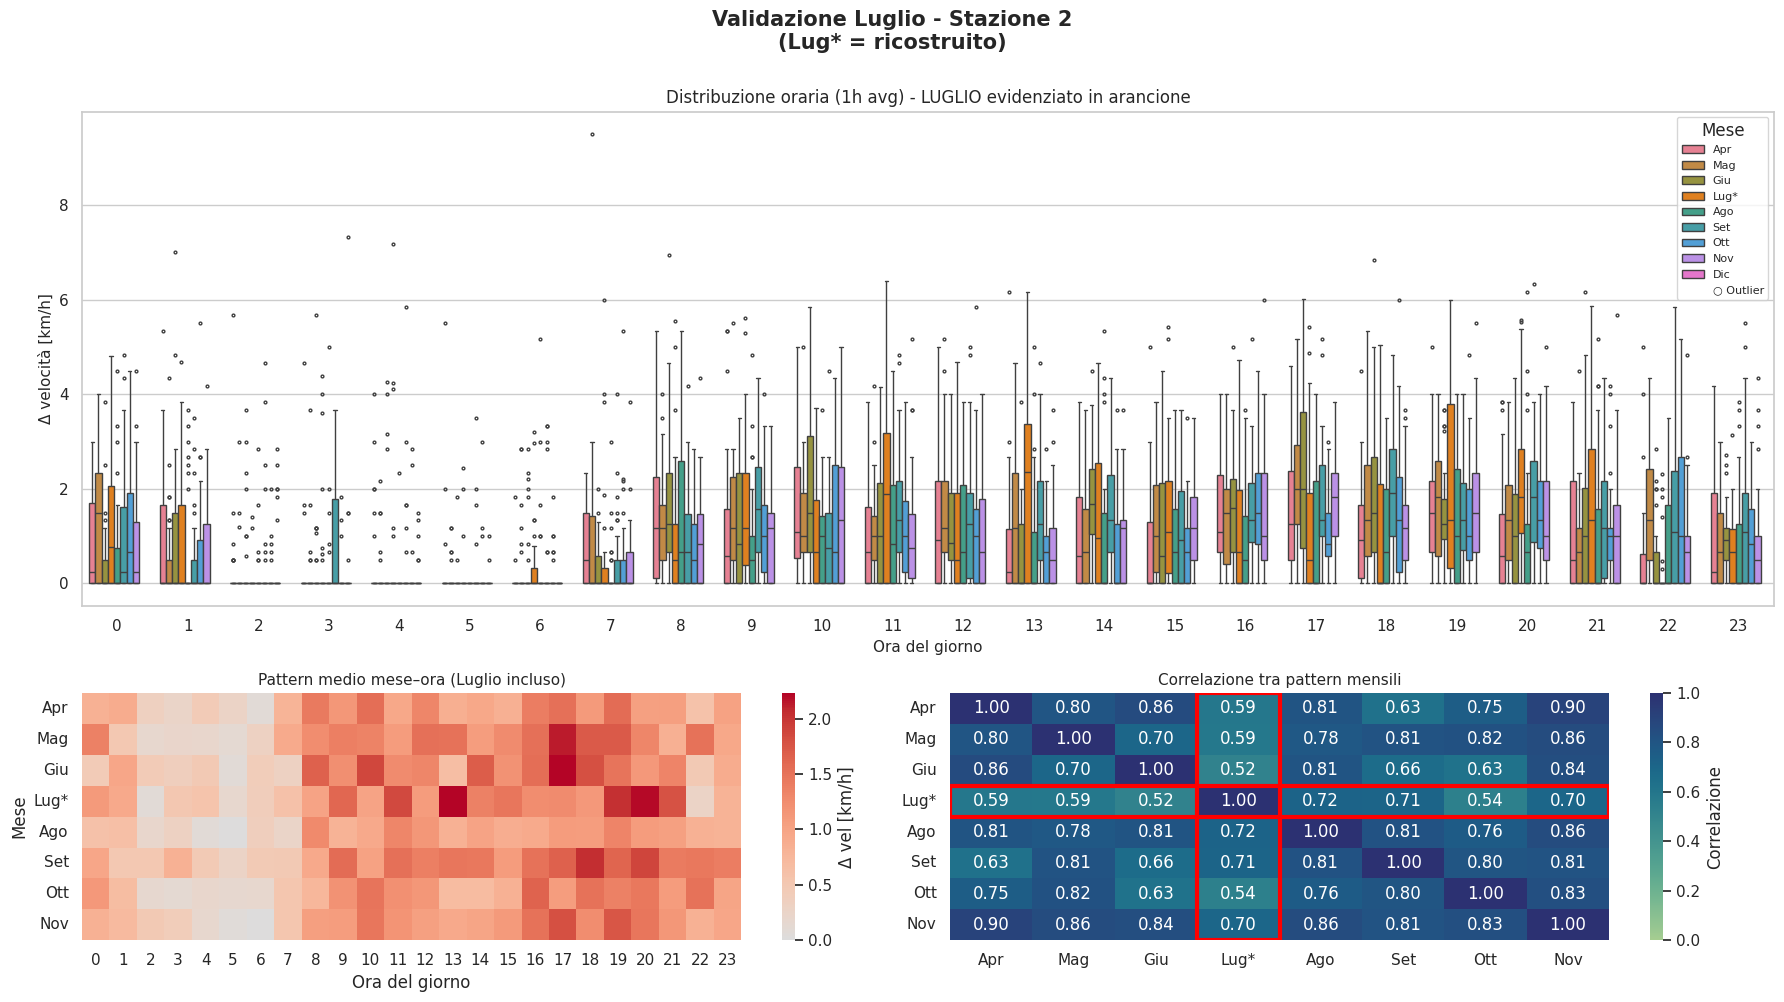


 Metriche di coerenza per Stazione 2:
  • Correlazione Luglio con altri mesi:
    ! Apr: 0.590
    ! Mag: 0.589
    ! Giu: 0.518
    ✓ Ago: 0.717
    ✓ Set: 0.708
    ! Ott: 0.538
    ✓ Nov: 0.703
  • Media correlazione: 0.623
  • Media Luglio: 1.11 km/h
  • Media altri mesi: 0.98 km/h
  • Differenza assoluta: 0.13 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 3 ===


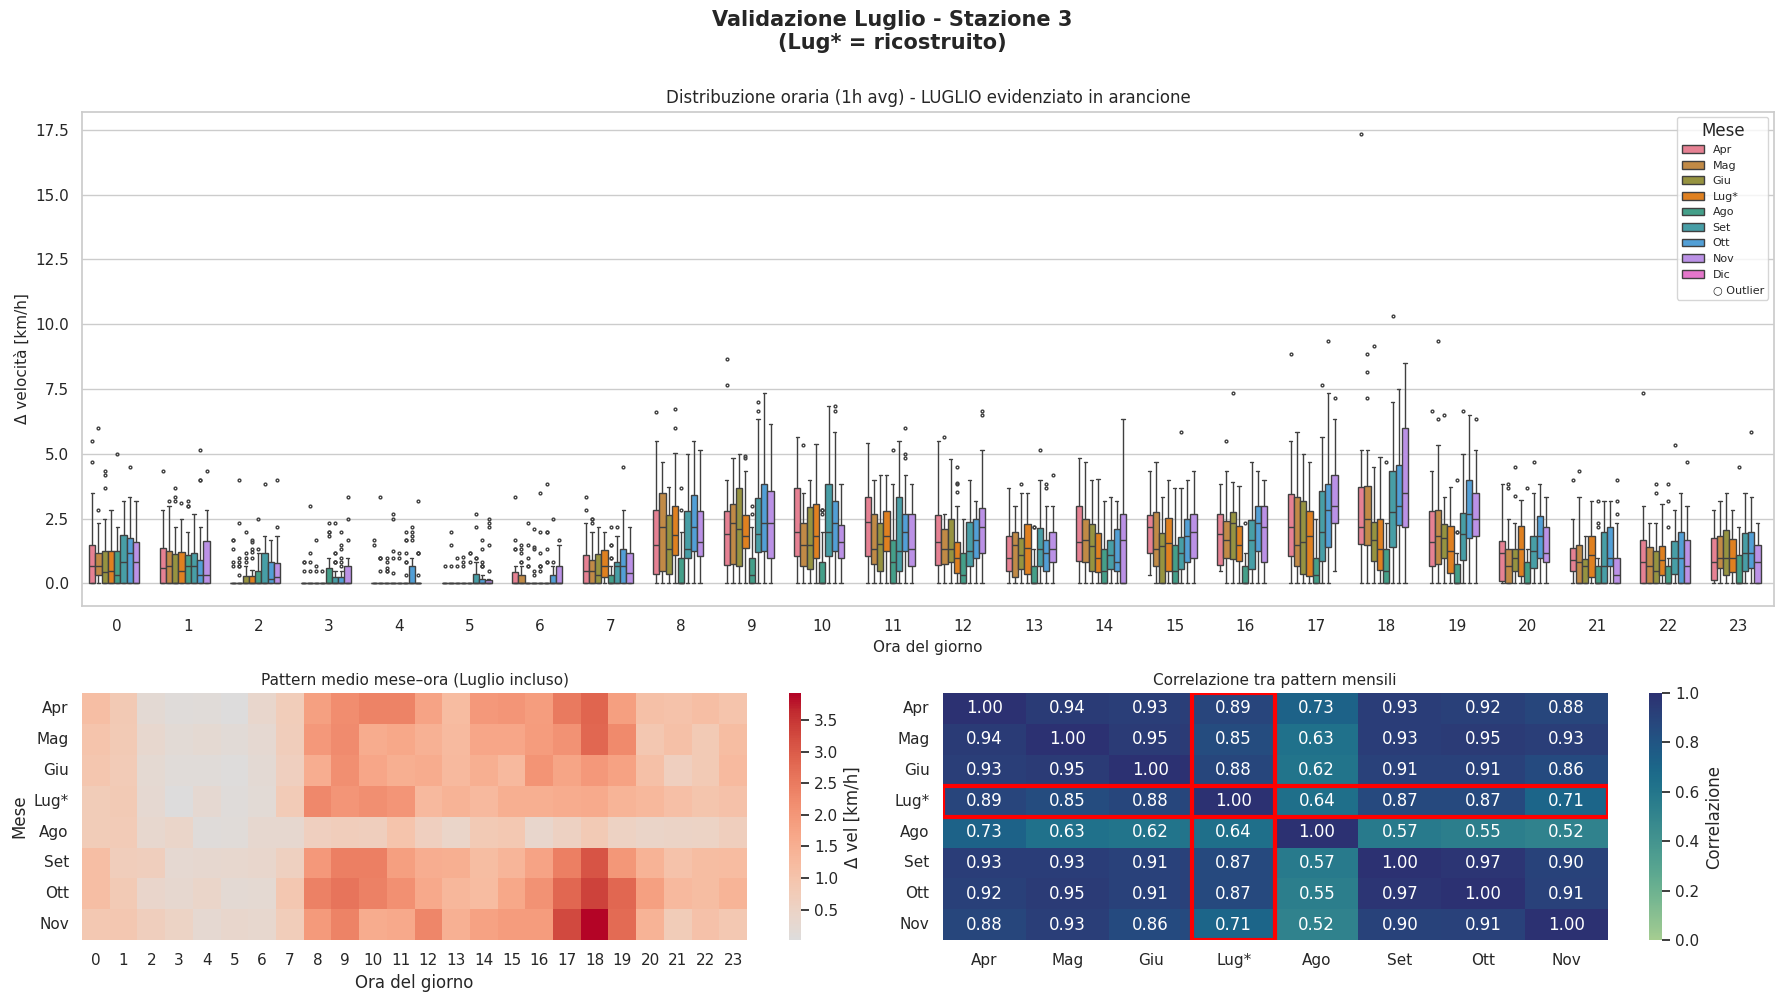


 Metriche di coerenza per Stazione 3:
  • Correlazione Luglio con altri mesi:
    ⭐ Apr: 0.894
    ⭐ Mag: 0.853
    ⭐ Giu: 0.883
    ! Ago: 0.642
    ⭐ Set: 0.869
    ⭐ Ott: 0.869
    ✓ Nov: 0.706
  • Media correlazione: 0.817
  • Media Luglio: 1.15 km/h
  • Media altri mesi: 1.23 km/h
  • Differenza assoluta: 0.08 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 4 ===


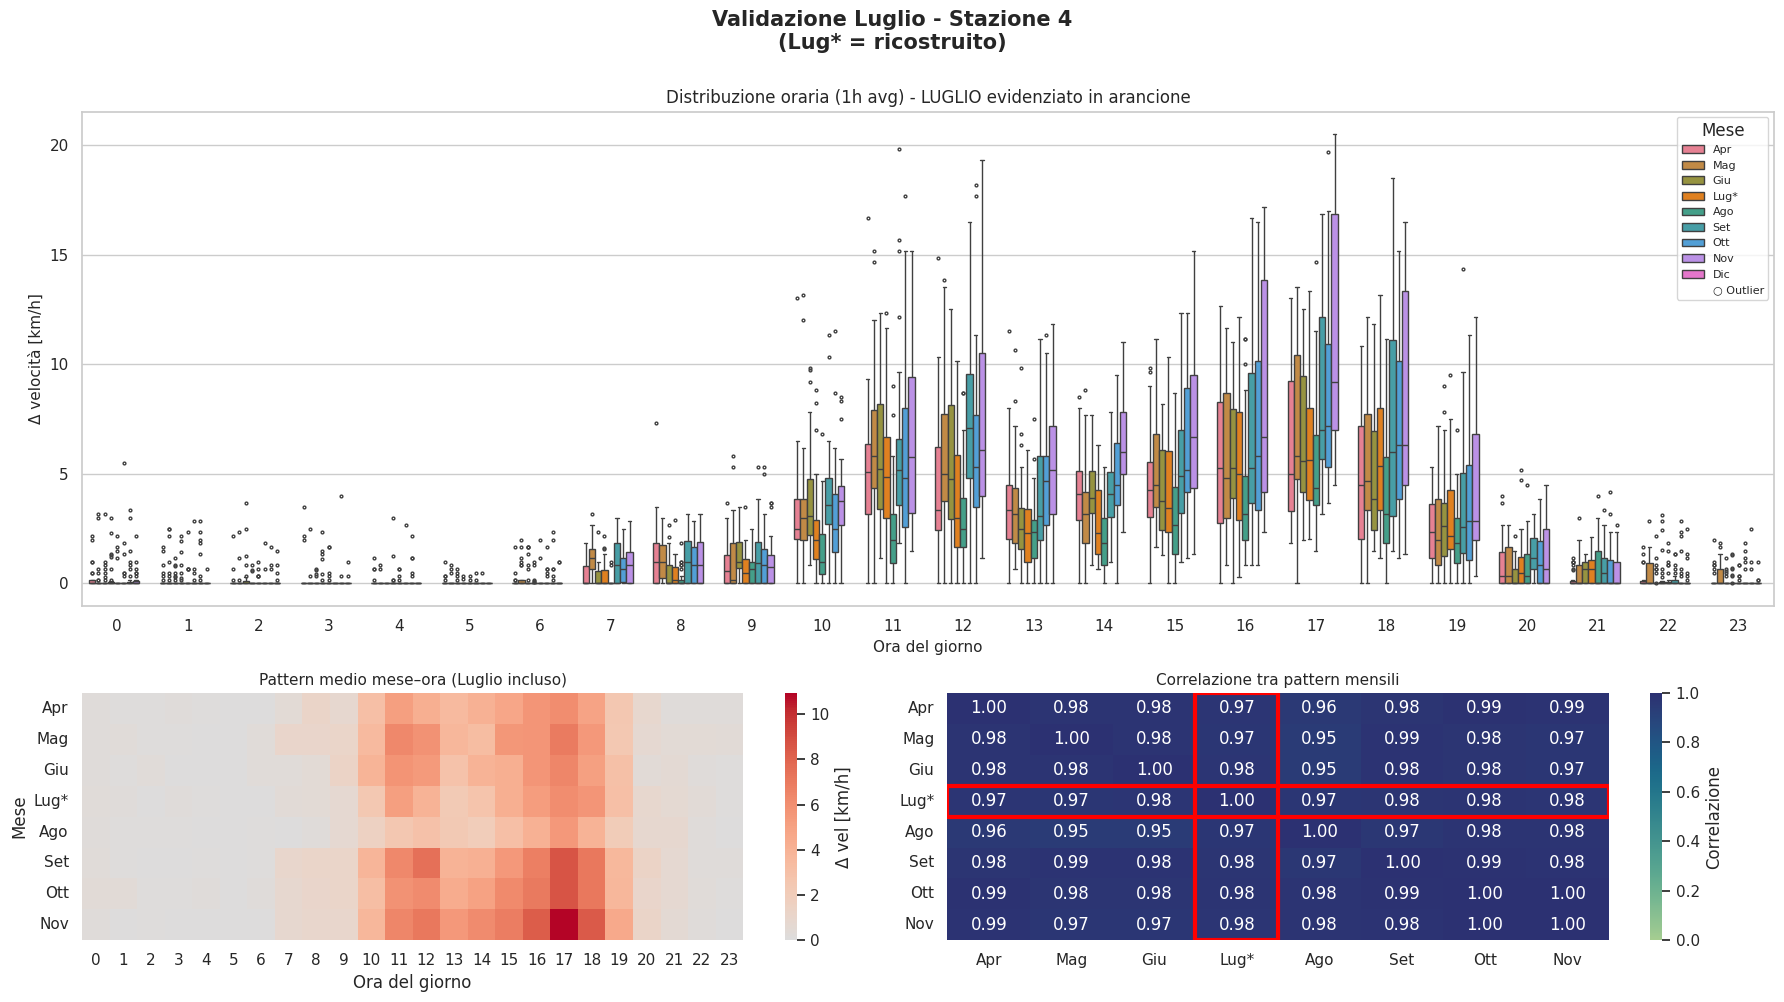


 Metriche di coerenza per Stazione 4:
  • Correlazione Luglio con altri mesi:
    ⭐ Apr: 0.975
    ⭐ Mag: 0.972
    ⭐ Giu: 0.975
    ⭐ Ago: 0.969
    ⭐ Set: 0.980
    ⭐ Ott: 0.982
    ⭐ Nov: 0.976
  • Media correlazione: 0.976
  • Media Luglio: 1.91 km/h
  • Media altri mesi: 2.31 km/h
  • Differenza assoluta: 0.40 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 5 ===


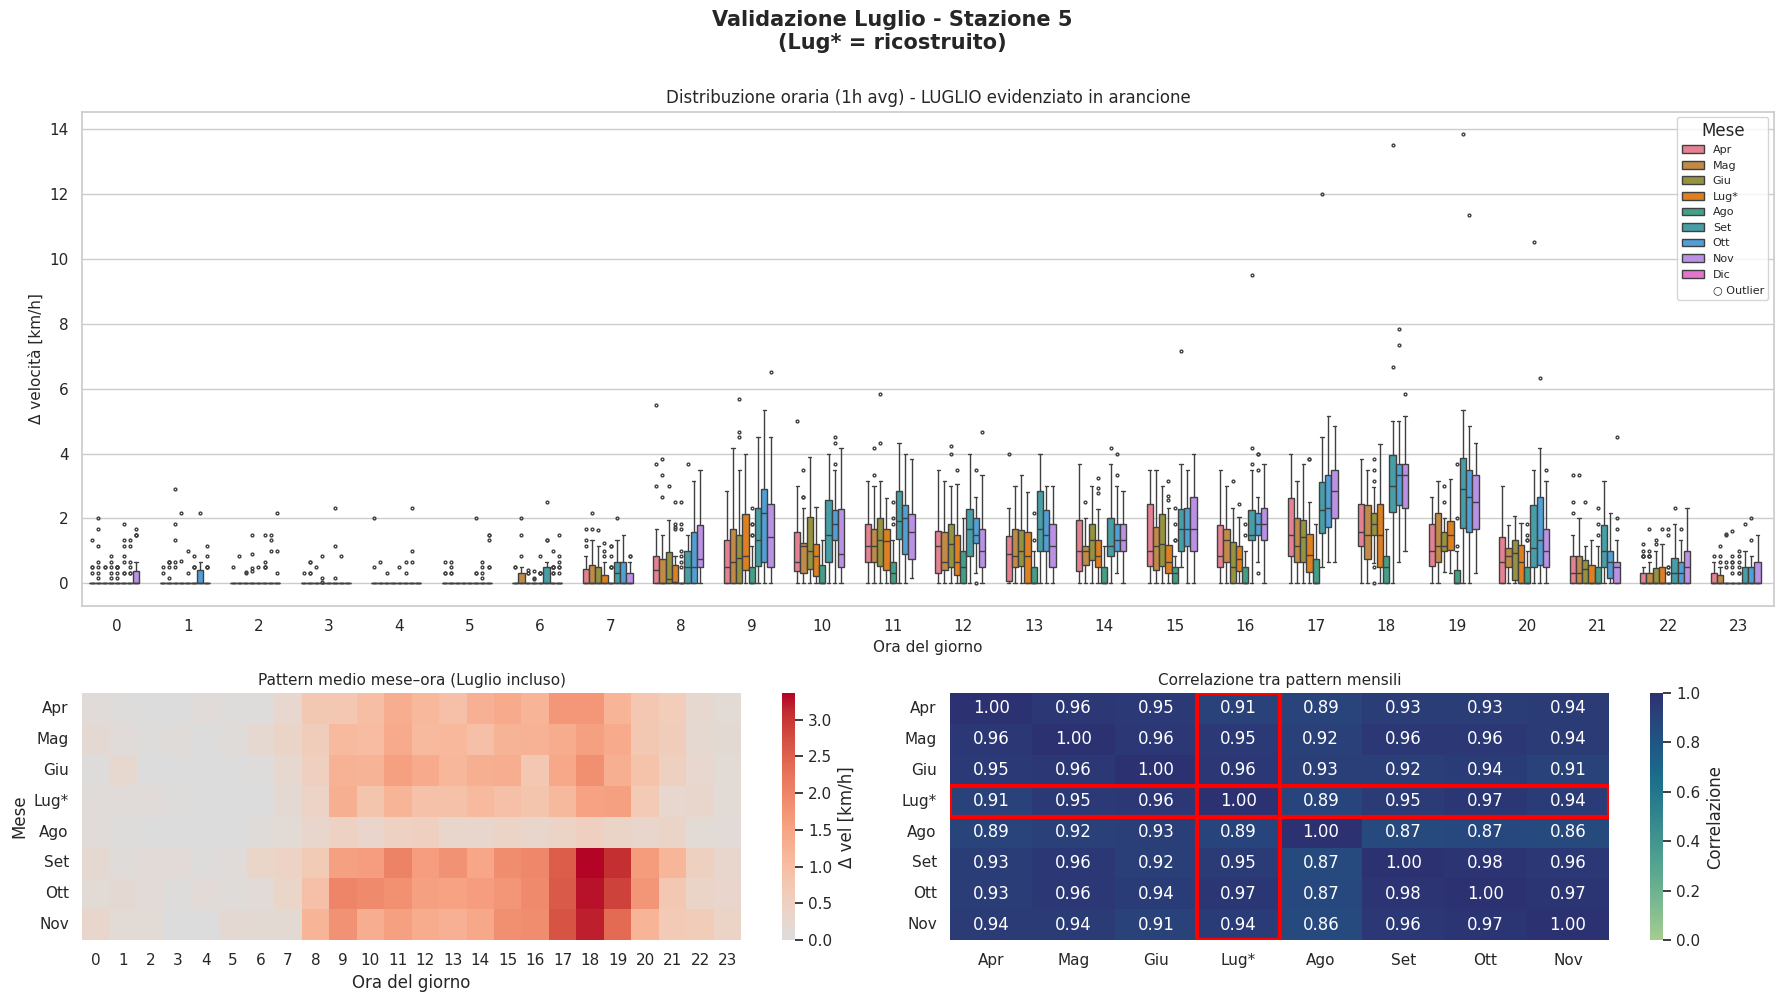


 Metriche di coerenza per Stazione 5:
  • Correlazione Luglio con altri mesi:
    ⭐ Apr: 0.910
    ⭐ Mag: 0.953
    ⭐ Giu: 0.958
    ⭐ Ago: 0.889
    ⭐ Set: 0.946
    ⭐ Ott: 0.966
    ⭐ Nov: 0.938
  • Media correlazione: 0.937
  • Media Luglio: 0.61 km/h
  • Media altri mesi: 0.82 km/h
  • Differenza assoluta: 0.22 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 6 ===


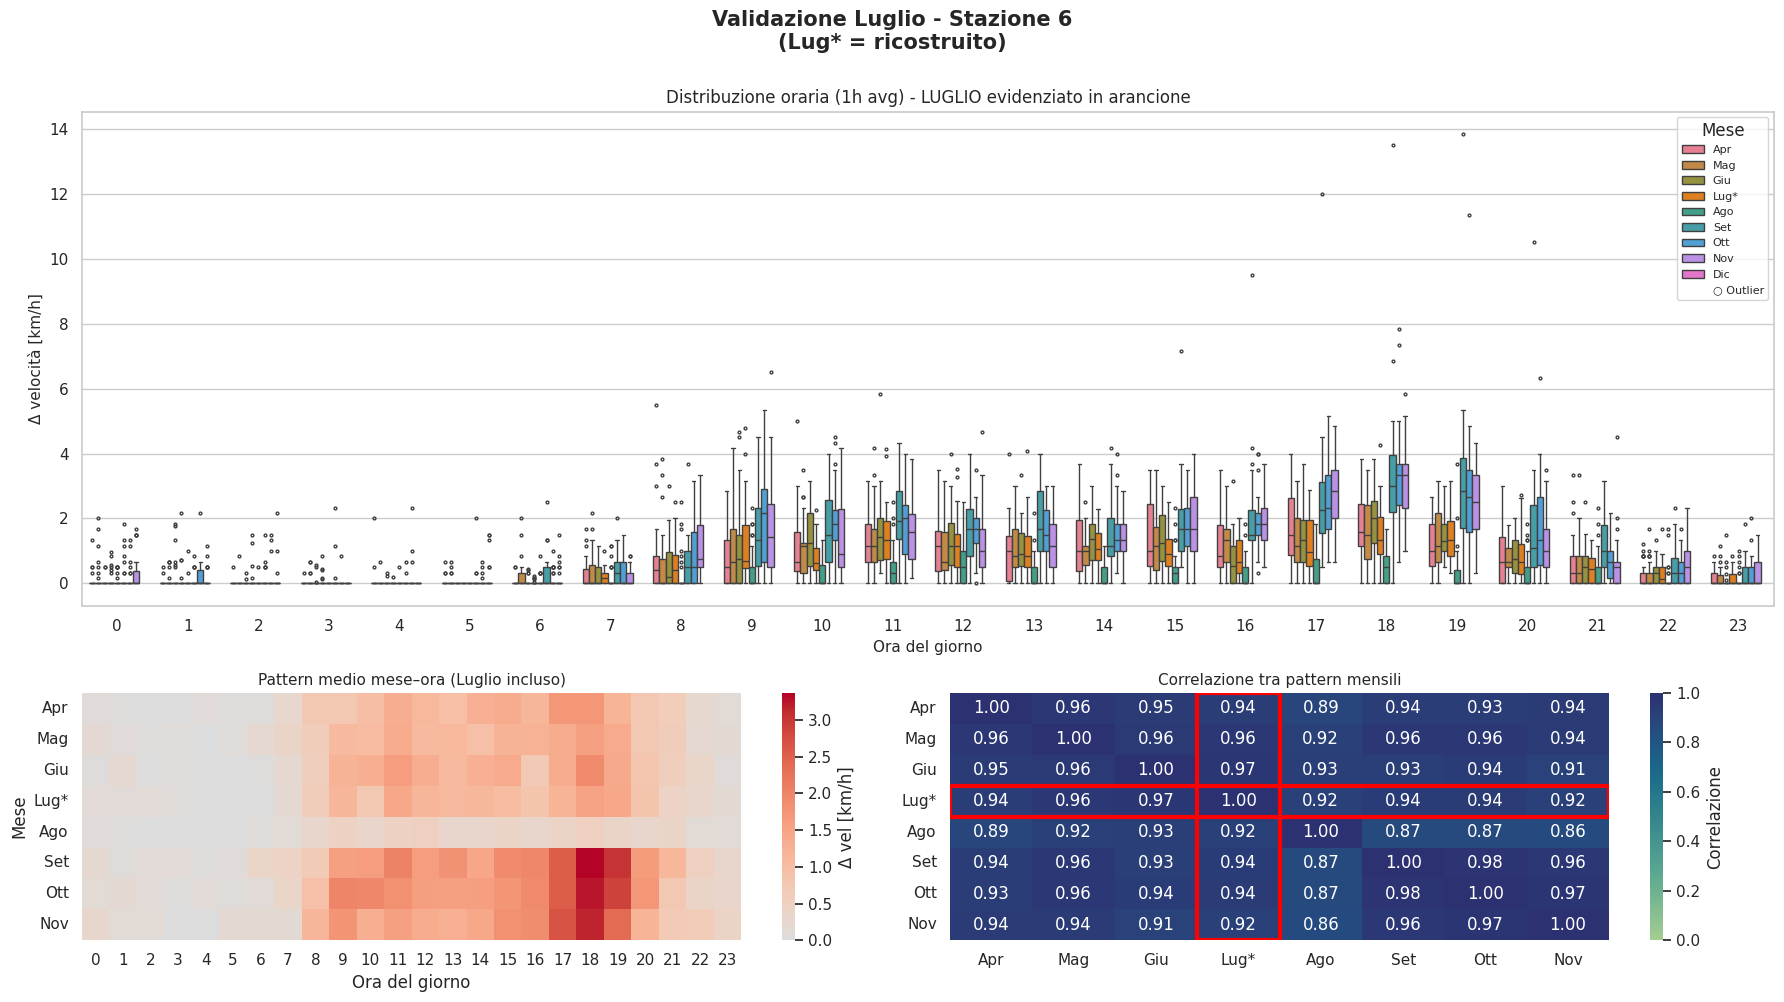


 Metriche di coerenza per Stazione 6:
  • Correlazione Luglio con altri mesi:
    ⭐ Apr: 0.937
    ⭐ Mag: 0.962
    ⭐ Giu: 0.970
    ⭐ Ago: 0.922
    ⭐ Set: 0.938
    ⭐ Ott: 0.944
    ⭐ Nov: 0.921
  • Media correlazione: 0.942
  • Media Luglio: 0.66 km/h
  • Media altri mesi: 0.82 km/h
  • Differenza assoluta: 0.17 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 7 ===


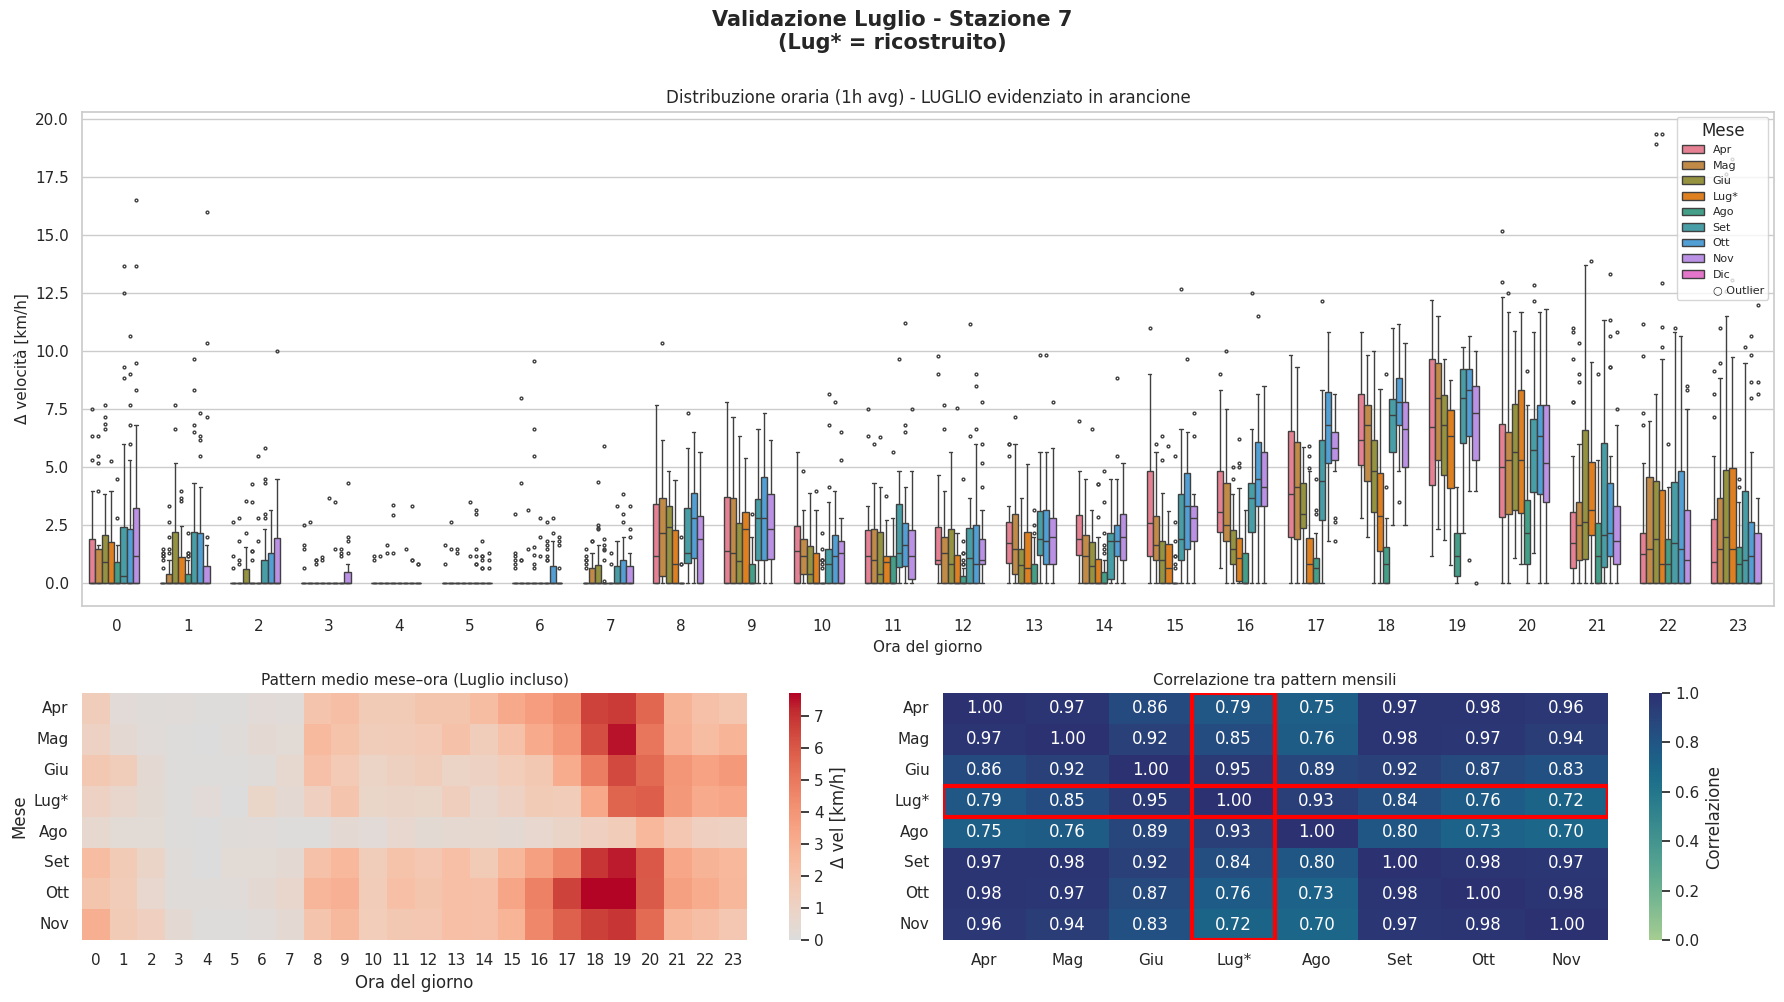


 Metriche di coerenza per Stazione 7:
  • Correlazione Luglio con altri mesi:
    ✓ Apr: 0.788
    ⭐ Mag: 0.850
    ⭐ Giu: 0.953
    ⭐ Ago: 0.929
    ⭐ Set: 0.843
    ✓ Ott: 0.763
    ✓ Nov: 0.718
  • Media correlazione: 0.835
  • Media Luglio: 1.69 km/h
  • Media altri mesi: 2.11 km/h
  • Differenza assoluta: 0.42 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 8 ===


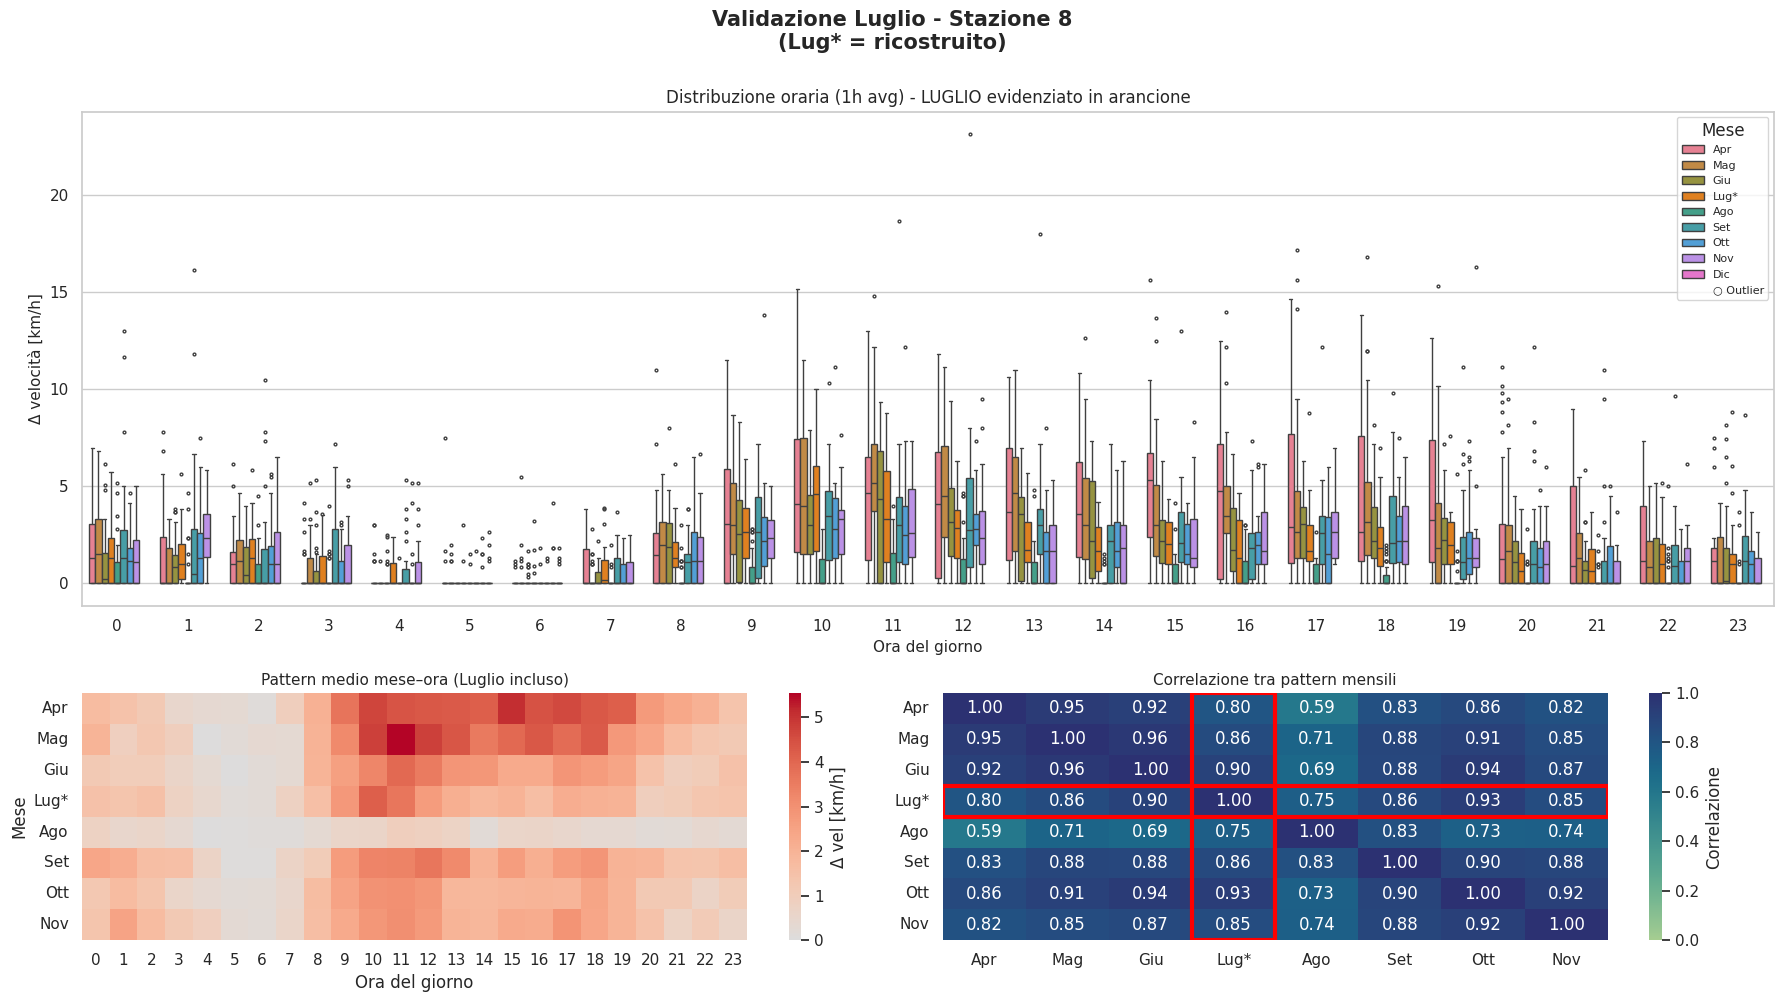


 Metriche di coerenza per Stazione 8:
  • Correlazione Luglio con altri mesi:
    ✓ Apr: 0.797
    ⭐ Mag: 0.856
    ⭐ Giu: 0.904
    ✓ Ago: 0.746
    ⭐ Set: 0.863
    ⭐ Ott: 0.932
    ⭐ Nov: 0.849
  • Media correlazione: 0.850
  • Media Luglio: 1.68 km/h
  • Media altri mesi: 1.82 km/h
  • Differenza assoluta: 0.14 km/h
  ➜ Luglio coerente con i volumi generali!

=== Analisi pattern per Stazione 9 ===


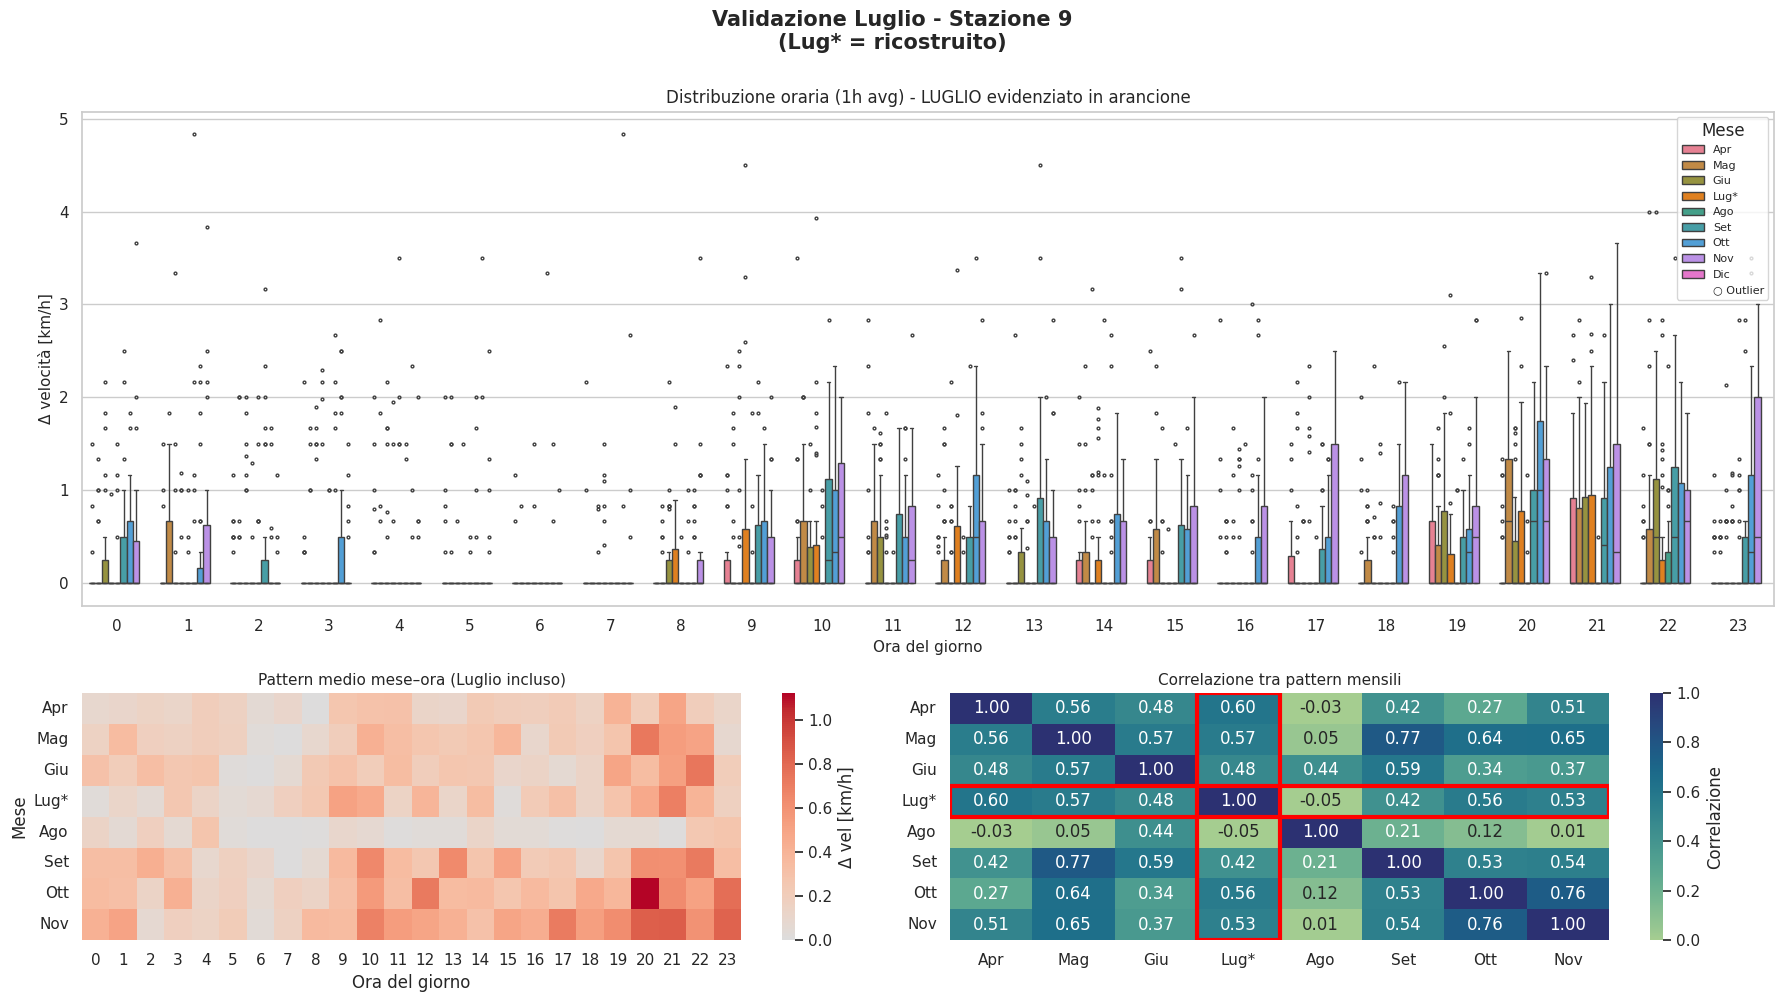


 Metriche di coerenza per Stazione 9:
  • Correlazione Luglio con altri mesi:
    ! Apr: 0.604
    ! Mag: 0.565
    ! Giu: 0.483
    ! Ago: -0.046
    ! Set: 0.424
    ! Ott: 0.565
    ! Nov: 0.533
  • Media correlazione: 0.447
  • Media Luglio: 0.24 km/h
  • Media altri mesi: 0.27 km/h
  • Differenza assoluta: 0.03 km/h
  ➜ Luglio coerente con i volumi generali!

 VALIDAZIONE MACRO COMPLETATA!

 Generazione confronto diretto: Giugno - Luglio - Settembre...


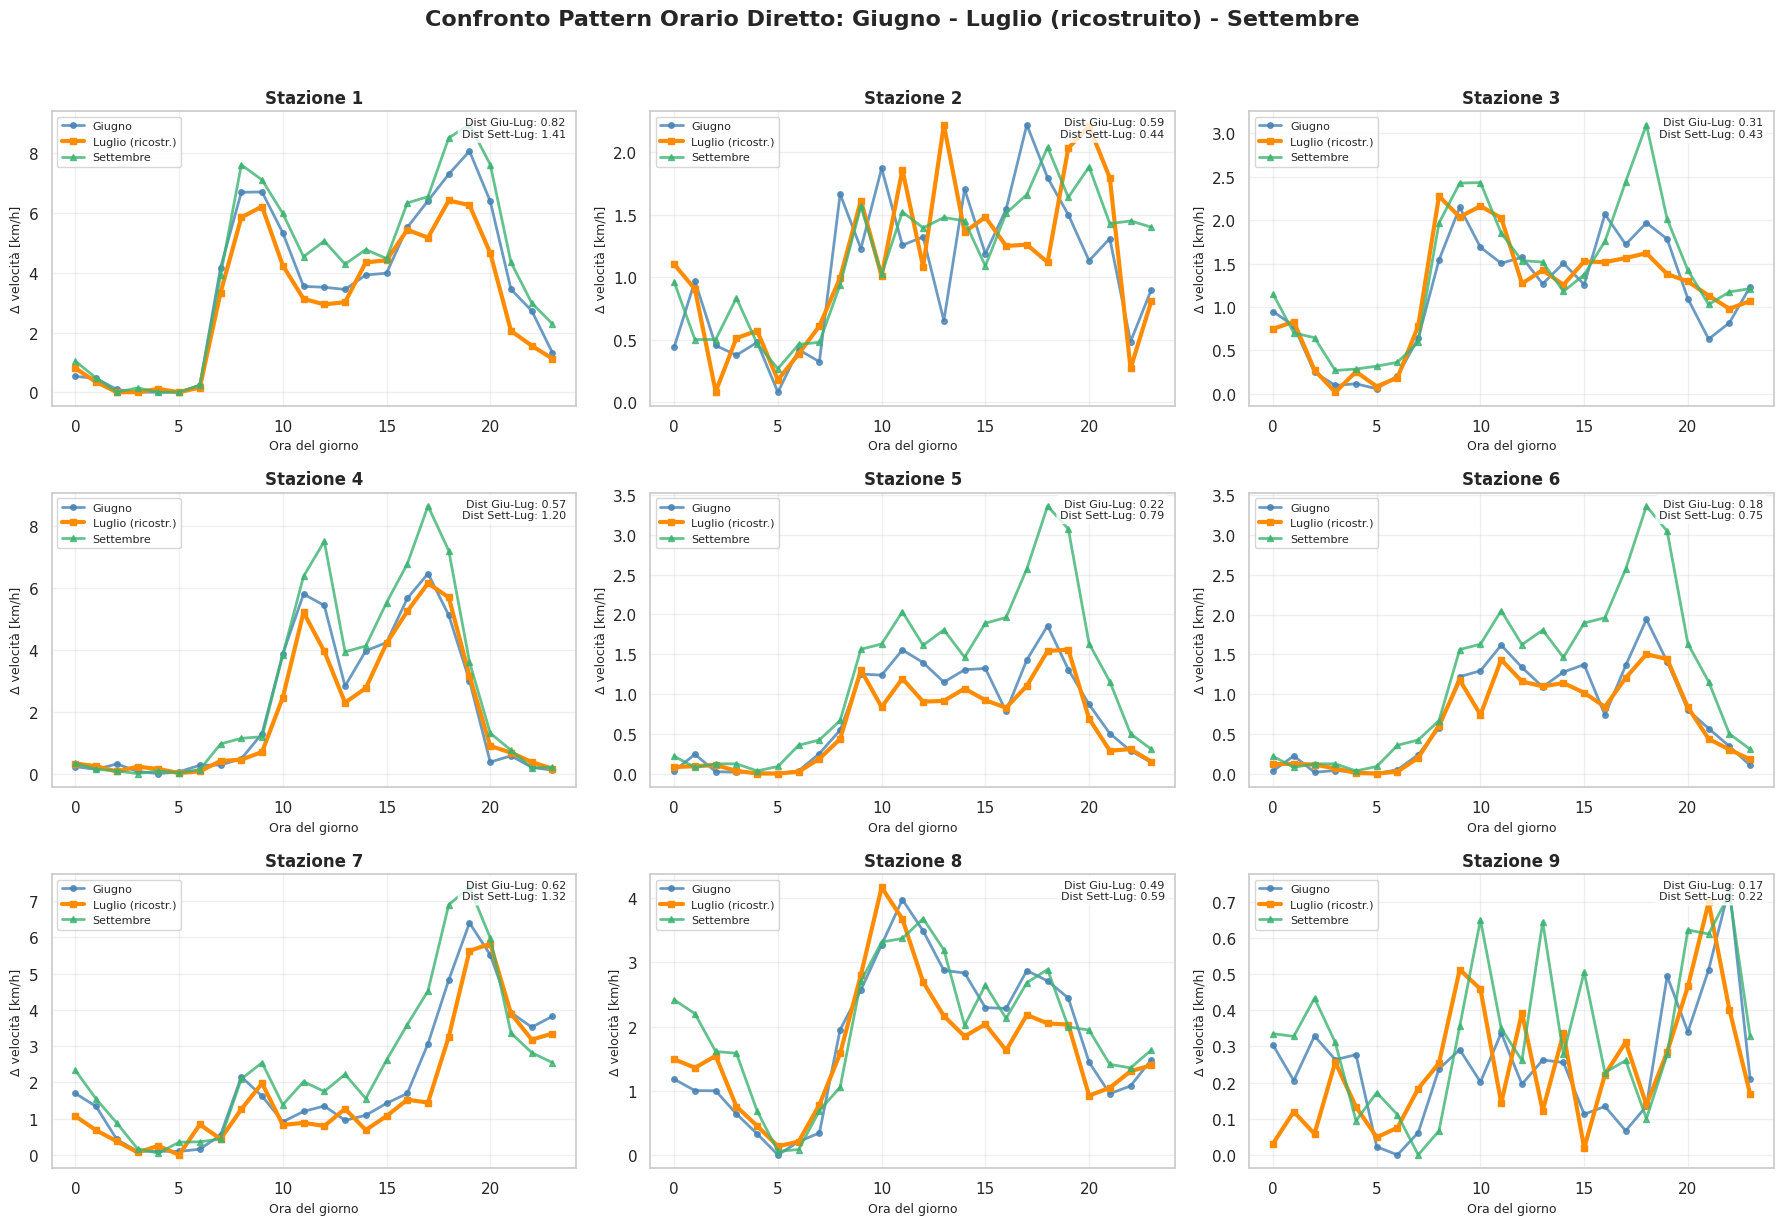


 Tutte le visualizzazioni completate!


In [43]:
# =====================================================
# 6. VALIDAZIONE PATTERN LUGLIO vs ALTRI MESI
# =====================================================

print("\n" + "="*70)
print(" VALIDAZIONE COERENZA LUGLIO RICOSTRUITO (MACRO-ANALISI)")
print("="*70)

# Prepara dati con luglio incluso
df_with_july = df_final.copy()
df_with_july['month'] = df_with_july['timestamp'].dt.month
df_with_july['hour'] = df_with_july['timestamp'].dt.hour

# Mappatura mesi INCLUSO LUGLIO (Assumendo storico da Aprile a Dicembre)
mesi_nomi_full = {4:'Apr', 5:'Mag', 6:'Giu', 7:'Lug*', 8:'Ago', 9:'Set', 10:'Ott', 11:'Nov', 12:'Dic'}
ordine_mesi_full = ['Apr', 'Mag', 'Giu', 'Lug*', 'Ago', 'Set', 'Ott', 'Nov', 'Dic']

df_with_july['month_name'] = pd.Categorical(
    df_with_july['month'].map(mesi_nomi_full),
    categories=ordine_mesi_full, ordered=True
)

stazioni = sorted(df_with_july['id_stazione'].unique())

# --- GRAFICI PER OGNI STAZIONE ---
for st in stazioni:
    df_st = df_with_july[df_with_july['id_stazione'] == st].copy()
    nome_stazione = f"Stazione {st}"

    print(f"\n=== Analisi pattern per {nome_stazione} ===")

    # Resample orario per stabilizzare la visualizzazione
    df_st_resampled = (
        df_st.set_index('timestamp')
        .resample('1h')['differenza']
        .mean()
        .fillna(0)
        .reset_index()
    )

    # Ricalcola campi temporali
    df_st_resampled['month'] = df_st_resampled['timestamp'].dt.month
    df_st_resampled['hour'] = df_st_resampled['timestamp'].dt.hour
    df_st_resampled['month_name'] = pd.Categorical(
        df_st_resampled['month'].map(mesi_nomi_full),
        categories=ordine_mesi_full, ordered=True
    )

    # --- CREA FIGURA: Box, Heatmap, Correlazione ---
    fig = plt.figure(figsize=(18, 10))
    gs = fig.add_gridspec(2, 2, height_ratios=[2, 1])
    fig.suptitle(f"Validazione Luglio - {nome_stazione}\n(Lug* = ricostruito)",
                 fontsize=15, y=1.00, fontweight='bold')

    # --- BOXPlot Orario per mese ---
    ax1 = fig.add_subplot(gs[0, :])

    # Palette standard Seaborn con Luglio forzato in evidenza
    palette = sns.color_palette("husl", len(ordine_mesi_full))
    try:
        july_idx_color = list(ordine_mesi_full).index('Lug*')
        palette[july_idx_color] = (1.0, 0.5, 0.0)  # Dark Orange
    except ValueError:
        pass

    sns.boxplot(
        data=df_st_resampled,
        x='hour', y='differenza', hue='month_name',
        palette=palette, ax=ax1, fliersize=2
    )
    ax1.set_title('Distribuzione oraria (1h avg) - LUGLIO evidenziato in arancione', fontsize=12)
    ax1.set_xlabel('Ora del giorno', fontsize=11)
    ax1.set_ylabel('Δ velocità [km/h]', fontsize=11)

    handles, labels = ax1.get_legend_handles_labels()
    import matplotlib.patches as mpatches
    outlier_patch = mpatches.Patch(color='none', label='○ Outlier')
    ax1.legend(handles=handles + [outlier_patch], title='Mese', fontsize=8, loc='upper right')

    # --- HEATMAP mese–ora ---
    pattern = (
        df_st_resampled.groupby(['month_name', 'hour'], observed=False)['differenza']
        .mean().unstack().dropna(how='all')
    )
    ax2 = fig.add_subplot(gs[1, 0])
    sns.heatmap(pattern, cmap='coolwarm', center=0, ax=ax2, cbar_kws={'label': 'Δ vel [km/h]'})
    ax2.set_title('Pattern medio mese–ora (Luglio incluso)', fontsize=11)
    ax2.set_xlabel('Ora del giorno')
    ax2.set_ylabel('Mese')

    # --- MATRICE DI CORRELAZIONE ---
    corr_df = pattern.T.corr()

    ax3 = fig.add_subplot(gs[1, 1])
    sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='crest',
                vmin=0, vmax=1, ax=ax3, cbar_kws={'label': 'Correlazione'})
    ax3.set_title('Correlazione tra pattern mensili', fontsize=11)
    ax3.set_xlabel('')
    ax3.set_ylabel('')

    # Evidenzia riga/colonna di Luglio se esiste nella matrice di correlazione
    if 'Lug*' in corr_df.index:
        july_idx_heatmap = list(corr_df.index).index('Lug*')
        ax3.add_patch(plt.Rectangle((july_idx_heatmap, 0), 1, len(corr_df.index),
                                    fill=False, edgecolor='red', lw=3))
        ax3.add_patch(plt.Rectangle((0, july_idx_heatmap), len(corr_df.columns), 1,
                                    fill=False, edgecolor='red', lw=3))

    plt.tight_layout()
    plt.show()

    # --- ANALISI TESTUALE ---
    print(f"\n Metriche di coerenza per {nome_stazione}:")

    if 'Lug*' in corr_df.index:
        july_corr = corr_df.loc['Lug*'].drop('Lug*')
        print(f"  • Correlazione Luglio con altri mesi:")
        for month, corr_val in july_corr.items():
            if pd.isna(corr_val):
                print(f"    - {month}: N/A (Varianza insufficiente)")
            else:
                symbol = "⭐" if corr_val > 0.8 else "✓" if corr_val > 0.7 else "!"
                print(f"    {symbol} {month}: {corr_val:.3f}")

        valid_corrs = july_corr.dropna()
        if not valid_corrs.empty:
            print(f"  • Media correlazione: {valid_corrs.mean():.3f}")
    else:
        print("  [!] Dati di Luglio insufficienti per calcolare le correlazioni mensili.")

    # Confronto statistiche
    july_data = df_st_resampled[df_st_resampled['month'] == 7]['differenza']
    other_data = df_st_resampled[df_st_resampled['month'] != 7]['differenza']

    mean_jul = july_data.mean() if not july_data.empty else 0
    mean_oth = other_data.mean() if not other_data.empty else 0
    diff_means = abs(mean_jul - mean_oth)

    print(f"  • Media Luglio: {mean_jul:.2f} km/h")
    print(f"  • Media altri mesi: {mean_oth:.2f} km/h")
    print(f"  • Differenza assoluta: {diff_means:.2f} km/h")

    if diff_means < 1.0:
        print(f"  ➜ Luglio coerente con i volumi generali!")
    elif diff_means < 2.5:
        print(f"  ➜ Luglio presenta volumi fisiologicamente diversi (Calo estivo/Accettabile)")
    else:
        print(f"  ➜ Luglio presenta anomalie di volume significative")

print("\n" + "="*70)
print(" VALIDAZIONE MACRO COMPLETATA!")
print("="*70)

# =====================================================
# CONFRONTO DIRETTO LUGLIO vs GIUGNO/SETTEMBRE
# =====================================================

print("\n Generazione confronto diretto: Giugno - Luglio - Settembre...")

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()

from scipy.spatial.distance import euclidean

for i, st in enumerate(stazioni):
    ax = axes[i]
    df_st = df_with_july[df_with_july['id_stazione'] == st].copy()
    nome = f"Stazione {st}"

    # Pattern orari per i 3 mesi centrali (Allineati a 24 ore)
    def get_hourly(df_month):
        s = df_month.groupby('hour')['differenza'].mean()
        return s.reindex(np.arange(24)).fillna(0)

    giugno = get_hourly(df_st[df_st['month'] == 6])
    luglio = get_hourly(df_st[df_st['month'] == 7])
    settembre = get_hourly(df_st[df_st['month'] == 9])

    # Plot
    ax.plot(giugno.index, giugno.values, 'o-', label='Giugno',
            linewidth=2, markersize=4, color='steelblue', alpha=0.8)
    ax.plot(luglio.index, luglio.values, 's-', label='Luglio (ricostr.)',
            linewidth=3, markersize=5, color='darkorange')
    ax.plot(settembre.index, settembre.values, '^-', label='Settembre',
            linewidth=2, markersize=4, color='mediumseagreen', alpha=0.8)

    ax.set_title(f"{nome}", fontsize=12, fontweight='bold')
    ax.set_xlabel('Ora del giorno', fontsize=9)
    ax.set_ylabel('Δ velocità [km/h]', fontsize=9)
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, alpha=0.3)

    # Calcola similarità (Distanza Euclidea Normalizzata)
    dist_giu_lug = euclidean(giugno.values, luglio.values) / np.sqrt(24)
    dist_ago_lug = euclidean(settembre.values, luglio.values) / np.sqrt(24)

    ax.text(0.98, 0.98, f'Dist Giu-Lug: {dist_giu_lug:.2f}\nDist Sett-Lug: {dist_ago_lug:.2f}',
            transform=ax.transAxes, fontsize=8, verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

for j in range(len(stazioni), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Confronto Pattern Orario Diretto: Giugno - Luglio (ricostruito) - Settembre",
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n Tutte le visualizzazioni completate!")